### Customer Support Ticket Analysis
### Member 1 – Data Cleaning and Quality Audit

### 1. Introduction

This notebook focuses on auditing, cleaning and validating the
Customer Support Ticket dataset before performing Exploratory
Data Analysis (EDA).

The main objective is to identify data-quality issues such as
missing values, duplicate records, blank strings, inconsistent
categories, invalid data types and timestamp errors.

The original dataset will be preserved, and a separate cleaned
analytical dataset will be created for further analysis.

### 2. Objectives

- Understand the dataset structure and attributes.
- Identify missing values and blank strings.
- Check duplicate records and Ticket IDs.
- Validate categorical and numerical columns.
- Parse and validate date and timestamp fields.
- Maintain a data-cleaning log.
- Generate a final data-quality report.
- Prepare a cleaned dataset for the remaining team members.

### 3. Tools and Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- VS Code / Jupyter Notebook

### 3.1 Importing Required Libraries

### Description

Import the Python libraries required for data manipulation,
numerical operations and data visualisation.

Pandas is used for dataset loading and cleaning.
NumPy supports numerical operations and missing-value handling.
Matplotlib and Seaborn are included for visual inspection
where required.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

### 4. Loading the Original Dataset

### Description

Load the customer support ticket CSV file using Pandas.

An unchanged copy of the original dataset is maintained
as df_raw. A separate working copy named df is created
for cleaning operations.

This ensures that the original source data remains protected.

In [2]:
from pathlib import Path

FILE_NAME = "customer_support_tickets.csv"

# Look in the current folder, the notebook's parent folder and the Downloads folder.
search_dirs = [Path.cwd(), Path.cwd().parent, Path.home() / "Downloads"]
DATA_PATH = next((str(d / FILE_NAME) for d in search_dirs if (d / FILE_NAME).exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        f"'{FILE_NAME}' was not found. Searched: {[str(d) for d in search_dirs]}. "
        "Copy the CSV into the same folder as this notebook "
        f"({Path.cwd()}) or set DATA_PATH manually, e.g. DATA_PATH = r'C:\\path\\to\\{FILE_NAME}'."
    )

print("Using dataset:", DATA_PATH)

df_raw = pd.read_csv(DATA_PATH)

df = df_raw.copy()

# Personal columns are excluded from every on-screen preview.
pii_columns = ["Customer Name", "Customer Email", "Ticket Description"]

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)
display(df.drop(columns=pii_columns).head())


Using dataset: c:\Users\phanindra\OneDrive\Desktop\calibo_teja_2026\calibo hackthon\customer_support_tickets.csv
Dataset loaded successfully
Dataset shape: (8469, 17)


,Ticket ID,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaN,NaN
1,2,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaN,NaN
2,3,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0
3,4,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0
4,5,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0


### 5. Initial Dataset Inspection

### Description

Inspect the structure and dimensions of the dataset to
understand its size, columns and data types.

This step helps identify whether the columns are stored
in appropriate formats before performing cleaning.

In [3]:
print("Dataset Dimensions:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Dimensions:
(8469, 17)

Column Names:
['Ticket ID', 'Customer Name', 'Customer Email', 'Customer Age', 'Customer Gender', 'Product Purchased', 'Date of Purchase', 'Ticket Type', 'Ticket Subject', 'Ticket Description', 'Ticket Status', 'Resolution', 'Ticket Priority', 'Ticket Channel', 'First Response Time', 'Time to Resolution', 'Customer Satisfaction Rating']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8469 entries, 0 to 8468
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ticket ID                     8469 non-null   int64  
 1   Customer Name                 8469 non-null   object 
 2   Customer Email                8469 non-null   object 
 3   Customer Age                  8469 non-null   int64  
 4   Customer Gender               8469 non-null   object 
 5   Product Purchased             8469 non-null   object 
 6   Date of Purchase       

### 6. Statistical Summary

### Description

Generate descriptive statistics for numerical and
categorical columns.

This helps understand numerical ranges, category
frequencies, unique values and possible data issues.

In [4]:
display(df.drop(columns=pii_columns).describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Ticket ID,8469.0,NaN,NaN,NaN,4235.0,2444.934048,1.0,2118.0,4235.0,6352.0,8469.0
Customer Age,8469.0,NaN,NaN,NaN,44.026804,15.296112,18.0,31.0,44.0,57.0,70.0
Customer Gender,8469,3,Male,2896,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product Purchased,8469,42,Canon EOS,240,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date of Purchase,8469,730,2020-10-21,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ticket Type,8469,5,Refund request,1752,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ticket Subject,8469,16,Refund request,576,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ticket Status,8469,3,Pending Customer Response,2881,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Resolution,2769,2769,Case maybe show recently my computer follow.,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ticket Priority,8469,4,Medium,2192,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 7. Column Data Type and Unique Value Audit

### Description

Examine the data type and number of unique values
in every column.

This helps identify identifier fields, numerical
attributes and categorical fields that require
different cleaning approaches.

In [5]:
column_audit = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Unique Values": df.nunique().values
})

display(column_audit)

,Column,Data Type,Unique Values
0,Ticket ID,int64,8469
1,Customer Name,object,8028
2,Customer Email,object,8320
3,Customer Age,int64,53
4,Customer Gender,object,3
5,Product Purchased,object,42
6,Date of Purchase,object,730
7,Ticket Type,object,5
8,Ticket Subject,object,16
9,Ticket Description,object,8077


### 8. Missing Value Analysis

### Description

Identify missing values in every dataset column
and calculate their percentage.

Missing values are important because they affect
the availability of information for further analysis.

No missing values will be replaced with artificial values
or removed without justification.

In [6]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    "Missing Percentage",
    ascending=False
)

display(missing_summary)

,Missing Count,Missing Percentage
Customer Satisfaction Rating,5700,67.30
Time to Resolution,5700,67.30
Resolution,5700,67.30
First Response Time,2819,33.29
Ticket Description,0,0.00
Ticket Channel,0,0.00
Ticket Priority,0,0.00
Ticket Status,0,0.00
Ticket ID,0,0.00
Customer Name,0,0.00


### 9. Blank String Analysis

### Description

Check object-type columns for empty strings and
strings containing only spaces.

Blank strings may not be recognised as missing values
by the standard missing-value check.

This step identifies such entries before category
validation and cleaning.

In [7]:
object_columns = df.select_dtypes(
    include=["object", "string"]
).columns

blank_counts = {}

for col in object_columns:
    blank_counts[col] = (
        df[col].notna() &
        df[col].astype(str).str.strip().eq("")
    ).sum()

display(pd.Series(blank_counts, name="Blank Count"))

Customer Name          0
Customer Email         0
Customer Gender        0
Product Purchased      0
Date of Purchase       0
Ticket Type            0
Ticket Subject         0
Ticket Description     0
Ticket Status          0
Resolution             0
Ticket Priority        0
Ticket Channel         0
First Response Time    0
Time to Resolution     0
Name: Blank Count, dtype: int64

### 10. Categorical Data Validation and Standardisation

### Description

Inspect categorical fields for unexpected values,
inconsistent spelling and unnecessary spaces.

The original category labels are preserved.
Only leading and trailing spaces are removed
from categorical values when necessary.

No category is renamed without evidence.

In [8]:
category_columns = [
    "Customer Gender",
    "Product Purchased",
    "Ticket Type",
    "Ticket Subject",
    "Ticket Status",
    "Ticket Priority",
    "Ticket Channel"
]

for col in category_columns:
    df[col] = df[col].str.strip()

for col in category_columns:
    print("\n", col)
    print(df[col].value_counts(dropna=False))


 Customer Gender
Customer Gender
Male      2896
Female    2887
Other     2686
Name: count, dtype: int64

 Product Purchased
Product Purchased
Canon EOS                         240
GoPro Hero                        228
Nest Thermostat                   225
Philips Hue Lights                221
Amazon Echo                       221
LG Smart TV                       219
Sony Xperia                       217
Roomba Robot Vacuum               216
Apple AirPods                     213
LG OLED                           213
iPhone                            212
Sony 4K HDR TV                    210
Garmin Forerunner                 208
LG Washing Machine                208
Canon DSLR Camera                 206
Nikon D                           204
Nintendo Switch Pro Controller    203
Google Pixel                      203
Fitbit Charge                     202
Sony PlayStation                  202
HP Pavilion                       200
Microsoft Office                  200
Amazon Kindle        

### 11. Expected Category Validation

### Description

Validate the status, priority and communication channel
values against the categories specified in the hackathon guide.

This helps identify unexpected or incorrectly entered
category values before further analysis.

In [9]:
expected_categories = {
    "Ticket Status": [
        "Open",
        "Pending Customer Response",
        "Closed"
    ],
    "Ticket Priority": [
        "Critical",
        "High",
        "Medium",
        "Low"
    ],
    "Ticket Channel": [
        "Email",
        "Phone",
        "Social media",
        "Chat"
    ]
}

for col, expected in expected_categories.items():
    actual = set(df[col].dropna().unique())
    unexpected = actual - set(expected)

    print("\nColumn:", col)
    print("Unexpected categories:", unexpected)


Column: Ticket Status
Unexpected categories: set()

Column: Ticket Priority
Unexpected categories: set()

Column: Ticket Channel
Unexpected categories: set()


### 12. Duplicate Record Analysis

### Description

Check the dataset for duplicate complete records
and duplicate Ticket IDs separately.

Duplicate rows may represent repeated records,
while duplicate identifiers may indicate multiple
records associated with the same ticket.

Both checks are performed independently.

In [10]:
duplicate_rows = df.duplicated().sum()

duplicate_ticket_ids = df["Ticket ID"].duplicated().sum()

print("Duplicate complete rows:", duplicate_rows)
print("Duplicate Ticket IDs:", duplicate_ticket_ids)
print("Unique Ticket IDs:", df["Ticket ID"].nunique())

Duplicate complete rows: 0
Duplicate Ticket IDs: 0
Unique Ticket IDs: 8469


### 13. Numerical Data Validation

### Description

Validate numerical fields such as Customer Age
and Customer Satisfaction Rating.

Convert the columns safely into numerical formats
and check for values outside reasonable validation ranges.

Missing values are preserved and are not replaced with zero.

In [11]:
numeric_columns = [
    "Customer Age",
    "Customer Satisfaction Rating"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

invalid_age = (
    (df["Customer Age"] < 0) |
    (df["Customer Age"] > 120)
).sum()

invalid_rating = (
    ~df["Customer Satisfaction Rating"]
    .dropna()
    .between(1, 5)
).sum()

print("Invalid Age Values:", invalid_age)
print("Invalid Satisfaction Ratings:", invalid_rating)

display(df[numeric_columns].describe())

Invalid Age Values: 0
Invalid Satisfaction Ratings: 0


,Customer Age,Customer Satisfaction Rating
count,8469.000000,2769.000000
mean,44.026804,2.991333
std,15.296112,1.407016
min,18.000000,1.000000
25%,31.000000,2.000000
50%,44.000000,3.000000
75%,57.000000,4.000000
max,70.000000,5.000000


### 14. Date and Timestamp Validation

### Description

Convert Date of Purchase, First Response Time
and Time to Resolution into datetime formats.

Use error handling to identify malformed timestamps
without stopping the cleaning process.

Missing and invalid timestamps are counted separately.

Date of Purchase is retained only as a purchase date
and is not treated as ticket creation time.

In [12]:
date_columns = [
    "Date of Purchase",
    "First Response Time",
    "Time to Resolution"
]

timestamp_audit = []

for col in date_columns:
    original = df[col].copy()

    parsed = pd.to_datetime(
        original,
        errors="coerce"
    )

    invalid = (original.notna() & parsed.isna()).sum()

    timestamp_audit.append({
        "Column": col,
        "Missing": original.isna().sum(),
        "Invalid": invalid,
        "Valid": parsed.notna().sum()
    })

    df[col] = parsed

timestamp_summary = pd.DataFrame(timestamp_audit)

display(timestamp_summary)

,Column,Missing,Invalid,Valid
0,Date of Purchase,0,0,8469
1,First Response Time,2819,0,5650
2,Time to Resolution,5700,0,2769


### 15. Identifier Data Type Conversion

### Description

Convert Ticket ID into a string data type because
it represents a unique identifier rather than
a numerical measurement.

This prevents accidental numerical calculations
using ticket identifiers.

In [13]:
df["Ticket ID"] = df["Ticket ID"].astype("string")

print("Ticket ID Data Type:", df["Ticket ID"].dtype)
print("Unique Ticket IDs:", df["Ticket ID"].nunique())

Ticket ID Data Type: string
Unique Ticket IDs: 8469


### 16. Privacy Protection and Analytical Dataset Creation

### Description

The original dataset contains customer names,
email addresses and ticket descriptions.

As instructed in the hackathon guide, these fields
are excluded from the analytical dataset to protect
customer privacy and avoid unnecessary exposure
of personal information.

A separate analytical DataFrame is created while
the original dataset remains unchanged.

In [14]:
excluded_columns = [
    "Customer Name",
    "Customer Email",
    "Ticket Description"
]

df_clean = df.drop(
    columns=excluded_columns
).copy()

print("Excluded Columns:", excluded_columns)
print("Original Dataset Shape:", df_raw.shape)
print("Analytical Dataset Shape:", df_clean.shape)

display(df_clean.head())

Excluded Columns: ['Customer Name', 'Customer Email', 'Ticket Description']
Original Dataset Shape: (8469, 17)
Analytical Dataset Shape: (8469, 14)


,Ticket ID,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaT,NaN
1,2,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaT,NaN
2,3,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0
3,4,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0
4,5,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0


### 17. Data Cleaning Log

### Description

Maintain a structured record of the data-quality
issues identified and the actions taken.

The cleaning log provides transparency and
documentation of all major cleaning decisions.

It records missing values, duplicates, numerical
validation, timestamp validation and privacy handling.

In [15]:
unexpected_total = sum(
    len(set(df[col].dropna().unique()) - set(expected))
    for col, expected in expected_categories.items()
)
invalid_timestamps = sum(item["Invalid"] for item in timestamp_audit)

cleaning_log = pd.DataFrame([
    ["Missing Values", "Resolution",
     f"{df['Resolution'].isna().sum()} missing", "Preserved as missing"],

    ["Missing Values", "First Response Time",
     f"{df['First Response Time'].isna().sum()} missing", "Preserved as missing"],

    ["Missing Values", "Time to Resolution",
     f"{df['Time to Resolution'].isna().sum()} missing", "Preserved as missing"],

    ["Missing Values", "Customer Satisfaction Rating",
     f"{df['Customer Satisfaction Rating'].isna().sum()} missing", "Preserved as missing"],

    ["Blank Strings", "Object columns",
     f"{sum(blank_counts.values())} blank strings", "No action required"],

    ["Duplicates", "Complete rows",
     f"{duplicate_rows} duplicates", "No removal required"],

    ["Duplicates", "Ticket ID",
     f"{duplicate_ticket_ids} duplicates", "No removal required"],

    ["Categories", "Categorical fields",
     "No unexpected categories" if unexpected_total == 0
     else f"{unexpected_total} unexpected categories",
     "Original labels preserved"],

    ["Numeric Validation", "Customer Age",
     f"{int(df['Customer Age'].min())} to {int(df['Customer Age'].max())}", "Validated"],

    ["Numeric Validation", "Satisfaction Rating",
     f"{int(df['Customer Satisfaction Rating'].min())} to "
     f"{int(df['Customer Satisfaction Rating'].max())}", "Validated"],

    ["Timestamp Validation", "Date fields",
     f"{invalid_timestamps} invalid timestamps", "Converted to datetime"],

    ["Privacy", "Name, Email, Description",
     f"{len(excluded_columns)} columns excluded", "Removed from analytical copy"],

    ["Data Preservation", "Original CSV",
     "Source preserved", "No modification"]
], columns=[
    "Issue Type",
    "Column",
    "Finding",
    "Action Taken"
])

display(cleaning_log)

,Issue Type,Column,Finding,Action Taken
0,Missing Values,Resolution,5700 missing,Preserved as missing
1,Missing Values,First Response Time,2819 missing,Preserved as missing
2,Missing Values,Time to Resolution,5700 missing,Preserved as missing
3,Missing Values,Customer Satisfaction Rating,5700 missing,Preserved as missing
4,Blank Strings,Object columns,0 blank strings,No action required
5,Duplicates,Complete rows,0 duplicates,No removal required
6,Duplicates,Ticket ID,0 duplicates,No removal required
7,Categories,Categorical fields,No unexpected categories,Original labels preserved
8,Numeric Validation,Customer Age,18 to 70,Validated
9,Numeric Validation,Satisfaction Rating,1 to 5,Validated


### 18. Final Data Quality Summary

### Description

Create a consolidated summary of the original
and analytical datasets after the cleaning process.

This summary provides an overview of dataset size,
duplicate records, missing values and invalid numerical
values.

It helps verify that the cleaning process has been
performed without unnecessary record removal.

In [16]:
quality_summary = pd.DataFrame({
    "Data Quality Check": [
        "Total Records",
        "Original Columns",
        "Analytical Columns",
        "Duplicate Rows",
        "Duplicate Ticket IDs",
        "Total Missing Values",
        "Invalid Age Values",
        "Invalid Satisfaction Ratings",
        "Invalid Timestamp Values"
    ],

    "Result": [
        len(df_clean),
        len(df_raw.columns),
        len(df_clean.columns),
        df_raw.duplicated().sum(),
        df_raw["Ticket ID"].duplicated().sum(),
        df_clean.isnull().sum().sum(),
        ((df_clean["Customer Age"] < 0) |
         (df_clean["Customer Age"] > 120)).sum(),
        (~df_clean["Customer Satisfaction Rating"]
         .dropna().between(1, 5)).sum(),
        sum(item["Invalid"] for item in timestamp_audit)
    ]
})

display(quality_summary)

,Data Quality Check,Result
0,Total Records,8469
1,Original Columns,17
2,Analytical Columns,14
3,Duplicate Rows,0
4,Duplicate Ticket IDs,0
5,Total Missing Values,19919
6,Invalid Age Values,0
7,Invalid Satisfaction Ratings,0
8,Invalid Timestamp Values,0


### 19. Exporting Data Quality Reports

### Description

Save the data-cleaning log and final data-quality
summary as separate CSV files.

These files provide supporting documentation
for the team's final hackathon submission.

In [17]:
os.makedirs("reports", exist_ok=True)

cleaning_log.to_csv(
    "reports/data_cleaning_log.csv",
    index=False
)

quality_summary.to_csv(
    "reports/data_quality_summary.csv",
    index=False
)

print("Data cleaning log saved successfully")
print("Data quality summary saved successfully")

Data cleaning log saved successfully
Data quality summary saved successfully


### 20. Exporting the Cleaned Analytical Dataset

### Description

Export the final cleaned analytical DataFrame
as a separate CSV file.

This file will be shared with the remaining
team members for ticket-status, priority,
channel, response, resolution and satisfaction analysis.

The original dataset is not overwritten.

In [18]:
df_clean.to_csv(
    "cleaned_customer_support_tickets.csv",
    index=False
)

print("Cleaned dataset saved successfully")
print("Final dataset shape:", df_clean.shape)

Cleaned dataset saved successfully
Final dataset shape: (8469, 14)


### 21. Final Dataset Verification

### Description

Reload the exported analytical dataset and verify
that the saved file matches the expected dimensions.

Check the duplicate records and confirm that
the excluded customer-identifying columns
are not present.

This final step ensures that the exported dataset
is suitable for team-wide analysis.

In [19]:
verified_df = pd.read_csv(
    "cleaned_customer_support_tickets.csv"
)

print("Final Verification Results")
print("Rows:", verified_df.shape[0])
print("Columns:", verified_df.shape[1])
print("Duplicate Rows:", verified_df.duplicated().sum())

print(
    "Excluded Columns Present:",
    any(col in verified_df.columns for col in excluded_columns)
)

print("Original Dataset Preserved:", df_raw.equals(pd.read_csv(DATA_PATH)))

Final Verification Results
Rows: 8469
Columns: 14
Duplicate Rows: 0
Excluded Columns Present: False
Original Dataset Preserved: True


### 22. Conclusion

The customer support ticket dataset was successfully
audited, cleaned and validated.

The analysis included dataset inspection, missing-value
assessment, blank-string checks, duplicate detection,
categorical validation, numerical validation and
datetime conversion.

The original dataset was preserved, and a separate
analytical dataset containing 8,469 records and
14 columns was created.

Missing values were retained to maintain data integrity.
Customer Name, Customer Email and Ticket Description
were excluded from the analytical dataset to protect
customer privacy.

The data-cleaning log and quality summary were generated
to document all identified issues and cleaning decisions.

The cleaned dataset is ready for further Exploratory
Data Analysis by the remaining team members.

### Important Limitations

- No ticket-created timestamp is available.
- Response and resolution durations cannot be reliably
  calculated from the available fields.
- Missing satisfaction ratings must not be treated as zero.
- Date of Purchase is not a ticket-created timestamp.
- Observed data patterns must not be interpreted as
  proven causes.

### Member 2 – Ticket Status and Type Analyst

### 1. Introduction

This section focuses on analysing customer support ticket data using Python. The main objective is to identify the most common customer issues, understand ticket statuses, and compare different ticket types.

In [20]:
# Import Pandas for data analysis
import pandas as pd

# Import Matplotlib for creating charts
import matplotlib.pyplot as plt

# Import Seaborn for statistical visualizations
import seaborn as sns

# Import OS for creating folders and saving files
import os

### 2. Loading and Exploring the Dataset

In this step, we load the customer support ticket CSV file using the Pandas library.

- **Reading the CSV file:** We use `pd.read_csv()` to load the dataset into a DataFrame named `df`.
- **Displaying the first five records:** We use `df.drop(columns=personal_columns).head()` to view the first five rows and understand how the data is organized. Customer names, e-mail addresses and ticket descriptions are hidden for privacy.
- **Checking the dataset shape:** We use `df.shape` to find the total number of rows and columns in the dataset.
- **Displaying column names:** We use `df.columns.tolist()` to display all the column names available in the dataset.



In [21]:
# Read the customer support CSV dataset
df = pd.read_csv("customer_support_tickets.csv")

# Personal columns are hidden from the preview to protect customer privacy
personal_columns = ["Customer Name", "Customer Email", "Ticket Description"]

# Display the first five records
print("First Five Records (personal columns hidden):")
print(df.drop(columns=personal_columns).head())

# Display the total number of rows and columns
print("\nDataset Shape:")
print(df.shape)

# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())

First Five Records (personal columns hidden):
   Ticket ID  Customer Age Customer Gender Product Purchased Date of Purchase  \
0          1            32           Other        GoPro Hero       2021-03-22   
1          2            42          Female       LG Smart TV       2021-05-22   
2          3            48           Other          Dell XPS       2020-07-14   
3          4            27          Female  Microsoft Office       2020-11-13   
4          5            67          Female  Autodesk AutoCAD       2020-02-04   

       Ticket Type            Ticket Subject              Ticket Status  \
0  Technical issue             Product setup  Pending Customer Response   
1  Technical issue  Peripheral compatibility  Pending Customer Response   
2  Technical issue           Network problem                     Closed   
3  Billing inquiry            Account access                     Closed   
4  Billing inquiry                 Data loss                     Closed   

                

### 3. Checking Required Columns in the Dataset

In this step, we verify whether the important columns required for our analysis are available in the dataset.

- **Storing column names:** We create a list called `required_columns` containing three important columns: Ticket Type, Ticket Subject, and Ticket Status.
- **Checking column availability:** We use a `for` loop to check each column name one by one.
- **If condition:** We use `if column in df.columns` to check whether the column exists in the dataset.
- **Else condition:** If the column is not available, the program displays a message saying that the column is missing.


In [22]:
# Store the required column names
required_columns = [
    "Ticket Type",
    "Ticket Subject",
    "Ticket Status"
]

# Check whether all required columns exist
for column in required_columns:

    if column in df.columns:
        print(column, "is available")

    else:
        print(column, "is missing from dataset")

Ticket Type is available
Ticket Subject is available
Ticket Status is available


### 4. Ticket Type Analysis

In this step, we use the `value_counts()` function to count the number of tickets in each category. We use `idxmax()` and `max()` to identify the most frequently reported ticket type and its total number of tickets.

In [23]:
# ----------------------------------------
# TICKET TYPE ANALYSIS
# ----------------------------------------

# Count the number of tickets in each type
ticket_type_count = df["Ticket Type"].value_counts()

# Display the ticket type summary
print("\nTicket Type Analysis:")
print(ticket_type_count)

# Find the most frequently reported ticket type
most_common_type = ticket_type_count.idxmax()

# Find the number of tickets in that type
highest_type_count = ticket_type_count.max()

# Display the result
print("\nMost Frequently Reported Ticket Type:")
print(most_common_type)

print("Number of Tickets:", highest_type_count)


Ticket Type Analysis:
Ticket Type
Refund request          1752
Technical issue         1747
Cancellation request    1695
Product inquiry         1641
Billing inquiry         1634
Name: count, dtype: int64

Most Frequently Reported Ticket Type:
Refund request
Number of Tickets: 1752


### 5. Ticket Subject Analysis

In this step, we use the `value_counts()` function to count how many times each ticket subject appears in the dataset. We use `head(5)` to display the top five frequently reported subjects. Finally, we use `idxmax()` to identify the most commonly reported ticket subject.

In [24]:
# ----------------------------------------
# TICKET SUBJECT ANALYSIS
# ----------------------------------------

# Count the number of tickets for each subject
subject_count = df["Ticket Subject"].value_counts()

# Display all ticket subjects
print("\nTicket Subject Analysis:")
print(subject_count)

# Get the top five frequently reported subjects
top_5_subjects = subject_count.head(5)

# Display the top five subjects
print("\nTop 5 Frequently Reported Subjects:")
print(top_5_subjects)

# Find the most frequently reported subject
most_common_subject = subject_count.idxmax()

print("\nMost Common Ticket Subject:")
print(most_common_subject)


Ticket Subject Analysis:
Ticket Subject
Refund request              576
Software bug                574
Product compatibility       567
Delivery problem            561
Hardware issue              547
Battery life                542
Network problem             539
Installation support        530
Product setup               529
Payment issue               526
Product recommendation      517
Account access              509
Peripheral compatibility    496
Data loss                   491
Cancellation request        487
Display issue               478
Name: count, dtype: int64

Top 5 Frequently Reported Subjects:
Ticket Subject
Refund request           576
Software bug             574
Product compatibility    567
Delivery problem         561
Hardware issue           547
Name: count, dtype: int64

Most Common Ticket Subject:
Refund request


### 6. Ticket Status Analysis

In this step, we use the `value_counts()` function to count the number of tickets in each status, such as Open, Closed, and Pending Customer Response. We use `idxmax()` and `max()` to identify the most common ticket status and its total number of tickets. This helps us understand the overall status distribution of customer support tickets.

In [25]:
# ----------------------------------------
# TICKET STATUS ANALYSIS
# ----------------------------------------

# Count the number of tickets in each status
status_count = df["Ticket Status"].value_counts()

# Display ticket status summary
print("\nTicket Status Analysis:")
print(status_count)

# Find the most common ticket status
most_common_status = status_count.idxmax()

# Find the highest status count
highest_status_count = status_count.max()

# Display the result
print("\nMost Common Ticket Status:")
print(most_common_status)

print("Number of Tickets:", highest_status_count)


Ticket Status Analysis:
Ticket Status
Pending Customer Response    2881
Open                         2819
Closed                       2769
Name: count, dtype: int64

Most Common Ticket Status:
Pending Customer Response
Number of Tickets: 2881


### 7. Ticket Type vs Ticket Status Analysis

1. **Creating a comparison table:** We use `pd.crosstab()` to compare the Ticket Type and Ticket Status columns.
2. **Counting tickets:** It calculates the number of Open, Closed, and Pending tickets for each ticket type.
3. **Displaying the result:** We use `print()` to display the comparison table.


In [26]:
# ----------------------------------------
# TICKET TYPE VS TICKET STATUS ANALYSIS
# ----------------------------------------

# Create a comparison table
type_status = pd.crosstab(
    df["Ticket Type"],
    df["Ticket Status"]
)

# Display the comparison table
print("\nTicket Type vs Ticket Status:")
print(type_status)


Ticket Type vs Ticket Status:
Ticket Status         Closed  Open  Pending Customer Response
Ticket Type                                                  
Billing inquiry          544   539                        551
Cancellation request     516   582                        597
Product inquiry          533   532                        576
Refund request           596   564                        592
Technical issue          580   602                        565


### 8. Percentage Analysis

1. **Ticket Type Percentage:** We use `value_counts(normalize=True)` to calculate the percentage of each ticket type and multiply it by 100.
2. **Ticket Status Percentage:** We calculate the percentage of each ticket status, such as Open, Closed, and Pending Customer Response.
3. **Displaying Results:** We use `round(2)` to display the percentages up to two decimal places.



In [27]:
# ----------------------------------------
# PERCENTAGE ANALYSIS
# ----------------------------------------

# Calculate percentage of each ticket type
type_percentage = (
    df["Ticket Type"].value_counts(normalize=True) * 100
)

# Display ticket type percentages
print("\nTicket Type Percentage:")
print(type_percentage.round(2))


# Calculate percentage of each ticket status
status_percentage = (
    df["Ticket Status"].value_counts(normalize=True) * 100
)

# Display ticket status percentages
print("\nTicket Status Percentage:")
print(status_percentage.round(2))


Ticket Type Percentage:
Ticket Type
Refund request          20.69
Technical issue         20.63
Cancellation request    20.01
Product inquiry         19.38
Billing inquiry         19.29
Name: proportion, dtype: float64

Ticket Status Percentage:
Ticket Status
Pending Customer Response    34.02
Open                         33.29
Closed                       32.70
Name: proportion, dtype: float64


### 9. Creating Folders and Setting Chart Style

1. **Creating Charts Folder:** We use `os.makedirs()` to create a folder named `charts` to save all the generated graphs.
2. **Creating Results Folder:** We create a `results` folder to store the analysis summary tables.
3. **Setting Chart Style:** We use `sns.set_theme(style="whitegrid")` to set a clean white-grid background for better visualization.



In [28]:
# Create a folder to save charts
os.makedirs("charts", exist_ok=True)

# Create a folder to save summary tables
os.makedirs("results", exist_ok=True)

# Set the visual style for charts
sns.set_theme(style="whitegrid")

### 10. Ticket Type Distribution

In this step, we create a horizontal bar chart using Seaborn's `countplot()` to display the number of tickets in each category. We add a chart title and axis labels to make the visualization clear and understandable. The `tight_layout()` function adjusts the chart layout, and `savefig()` saves the chart as a PNG image in the charts folder. Finally, `show()` displays the chart.

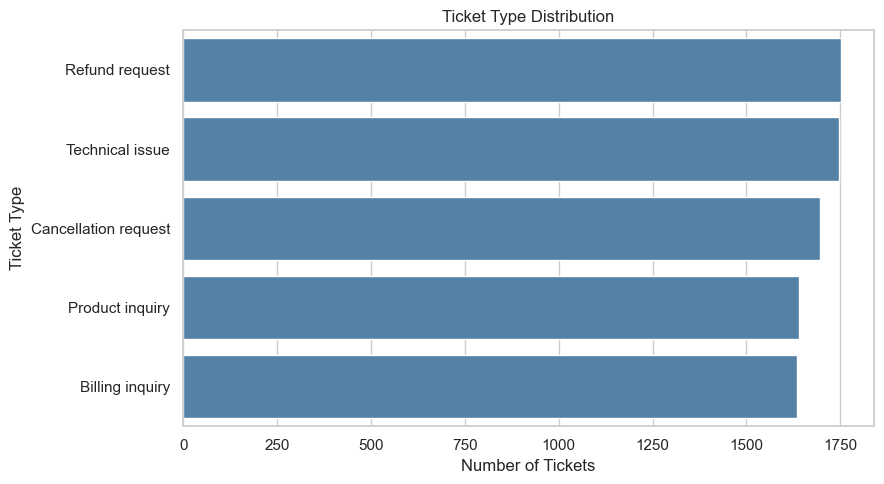

In [29]:
# ----------------------------------------
# CHART 1: TICKET TYPE DISTRIBUTION
# ----------------------------------------

# Set chart size
plt.figure(figsize=(9, 5))

# Create a horizontal bar chart
sns.countplot(
    color="steelblue",
    data=df,
    y="Ticket Type",
    order=df["Ticket Type"].value_counts().index
)

# Add chart title
plt.title("Ticket Type Distribution")

# Add X-axis label
plt.xlabel("Number of Tickets")

# Add Y-axis label
plt.ylabel("Ticket Type")

# Adjust chart layout
plt.tight_layout()

# Save the chart as an image
plt.savefig("charts/ticket_type_distribution.png")

# Display the chart
plt.show()

### 11. Ticket Status Distribution

In this step, we create a bar chart using Seaborn's `countplot()` to visualize the distribution of ticket statuses, such as Open, Closed, and Pending Customer Response. We add a chart title and axis labels to make the graph easy to understand. We use `xticks(rotation=15)` to slightly rotate the X-axis labels for better readability. Finally, we save the chart as a PNG image in the charts folder and display it using `show()`.

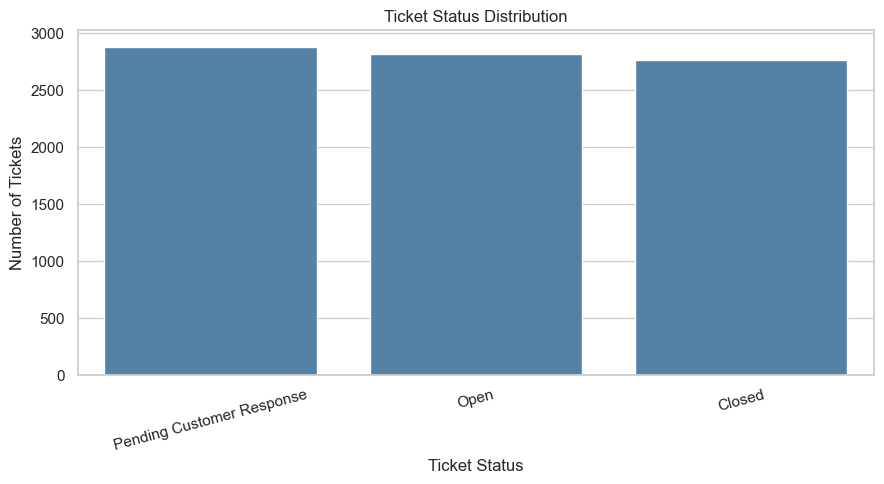

In [30]:
# ----------------------------------------
# CHART 2: TICKET STATUS DISTRIBUTION
# ----------------------------------------

# Set chart size
plt.figure(figsize=(9, 5))

# Create a bar chart
sns.countplot(
    color="steelblue",
    data=df,
    x="Ticket Status",
    order=df["Ticket Status"].value_counts().index
)

# Add title
plt.title("Ticket Status Distribution")

# Add axis labels
plt.xlabel("Ticket Status")
plt.ylabel("Number of Tickets")

# Rotate X-axis labels
plt.xticks(rotation=15)

# Adjust layout
plt.tight_layout()

# Save chart
plt.savefig("charts/ticket_status_distribution.png")

# Display chart
plt.show()

### 12. Ticket Subject Distribution

In this step, we create a horizontal bar chart using Seaborn's `countplot()` to visualize the number of tickets for each subject. We add a chart title and axis labels to make the graph easy to understand. The `tight_layout()` function adjusts the chart layout, and `savefig()` saves the chart as a PNG image in the charts folder. Finally, `show()` displays the chart.

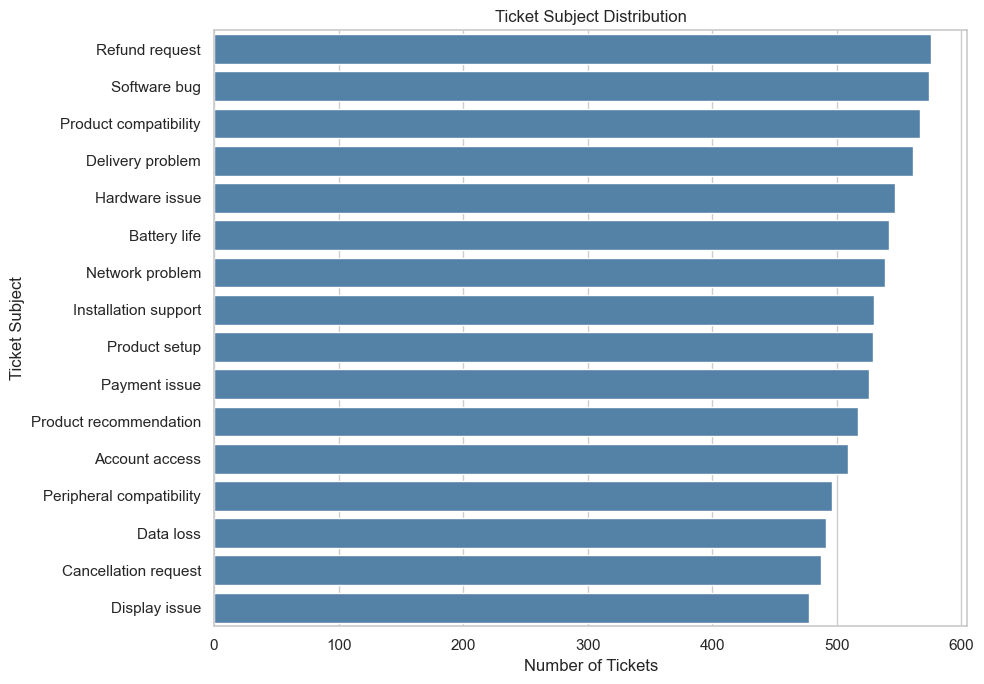

In [31]:
# ----------------------------------------
# CHART 3: TICKET SUBJECT DISTRIBUTION
# ----------------------------------------

# Set chart size
plt.figure(figsize=(10, 7))

# Create horizontal bar chart
sns.countplot(
    color="steelblue",
    data=df,
    y="Ticket Subject",
    order=df["Ticket Subject"].value_counts().index
)

# Add title
plt.title("Ticket Subject Distribution")

# Add axis labels
plt.xlabel("Number of Tickets")
plt.ylabel("Ticket Subject")

# Adjust layout
plt.tight_layout()

# Save chart
plt.savefig("charts/ticket_subject_distribution.png")

# Display chart
plt.show()

### 13. Ticket Type vs Ticket Status

In this step, we create a grouped bar chart using the `plot()` function to compare different ticket types with their statuses. The chart shows the number of Open, Closed, and Pending tickets for each ticket type. We add a title, axis labels, and a legend to make the comparison clear. Finally, we save the chart as a PNG image in the charts folder and display it using `show()`.

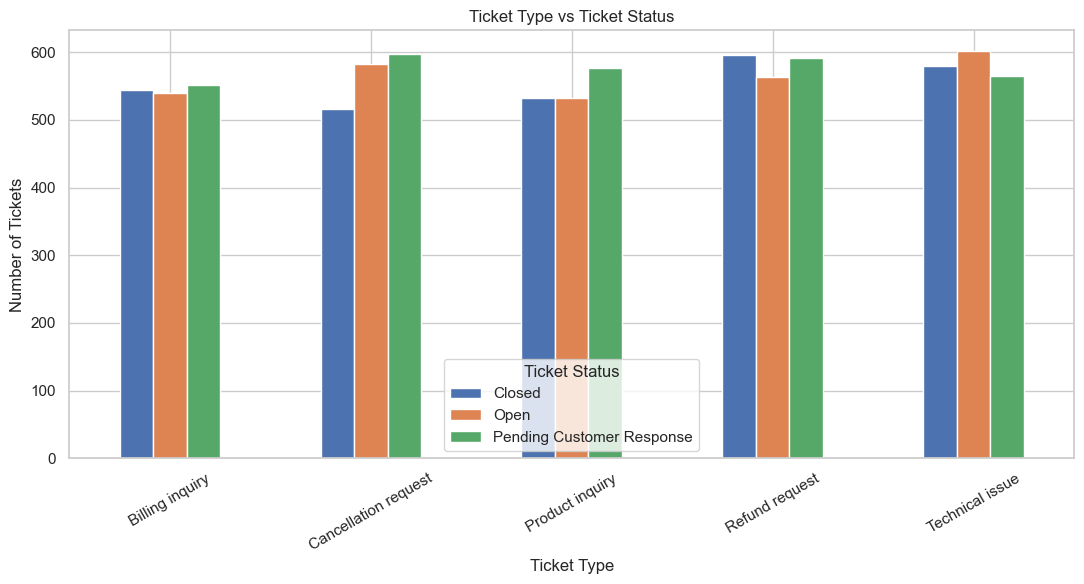

In [32]:
# ----------------------------------------
# CHART 4: TICKET TYPE VS TICKET STATUS
# ----------------------------------------

# Create a grouped bar chart from the comparison table
type_status.plot(
    kind="bar",
    figsize=(11, 6)
)

# Add chart title
plt.title("Ticket Type vs Ticket Status")

# Add axis labels
plt.xlabel("Ticket Type")
plt.ylabel("Number of Tickets")

# Rotate X-axis labels
plt.xticks(rotation=30)

# Add legend
plt.legend(title="Ticket Status")

# Adjust layout
plt.tight_layout()

# Save chart
plt.savefig("charts/ticket_type_vs_status.png")

# Display chart
plt.show()

### 14. Saving Analysis Summary Tables

In this step, we save all the analysis results as CSV files using the `to_csv()` function. These files include ticket type counts, ticket subject counts, ticket status counts, ticket type and status comparisons, and their percentage summaries. All files are stored in the `results` folder for future reference and easy sharing with other team members. Finally, we display a success message to confirm that the summary tables have been saved.

In [33]:
# ----------------------------------------
# SAVE SUMMARY TABLES
# ----------------------------------------

# Save ticket type count
ticket_type_count.to_csv(
    "results/ticket_type_summary.csv"
)

# Save ticket subject count
subject_count.to_csv(
    "results/ticket_subject_summary.csv"
)

# Save ticket status count
status_count.to_csv(
    "results/ticket_status_summary.csv"
)

# Save ticket type and status comparison
type_status.to_csv(
    "results/ticket_type_status_comparison.csv"
)

# Save ticket type percentages
type_percentage.to_csv(
    "results/ticket_type_percentage.csv"
)

# Save ticket status percentages
status_percentage.to_csv(
    "results/ticket_status_percentage.csv"
)

# Display success message
print("\nAll summary tables saved successfully!")


All summary tables saved successfully!


### 15. Generating Key Observations

In this step, we generate important findings from the ticket analysis using the `idxmax()` and `max()` functions. We identify the most common ticket type, the most frequently reported ticket subject, the most common ticket status, and the ticket type with the highest number of open tickets. These observations help us summarize the analysis results and understand the major trends in customer support tickets.

In [34]:
# ----------------------------------------
# GENERATE KEY OBSERVATIONS
# ----------------------------------------

print("\n========== KEY OBSERVATIONS ==========")

# Observation 1: Most common ticket type
print(
    "1. Most common ticket type:",
    ticket_type_count.idxmax(),
    "with",
    ticket_type_count.max(),
    "tickets."
)

# Observation 2: Most common ticket subject
print(
    "2. Most common ticket subject:",
    subject_count.idxmax(),
    "with",
    subject_count.max(),
    "tickets."
)

# Observation 3: Most common ticket status
print(
    "3. Most common ticket status:",
    status_count.idxmax(),
    "with",
    status_count.max(),
    "tickets."
)

# Observation 4: Ticket type with highest open count
print(
    "4. Ticket type with highest open tickets:",
    type_status["Open"].idxmax(),
    "with",
    type_status["Open"].max(),
    "open tickets."
)

print("======================================")


========== KEY OBSERVATIONS ==========
1. Most common ticket type: Refund request with 1752 tickets.
2. Most common ticket subject: Refund request with 576 tickets.
3. Most common ticket status: Pending Customer Response with 2881 tickets.
4. Ticket type with highest open tickets: Technical issue with 602 open tickets.


### 16. Conclusion
The analysis of customer support tickets helped us understand the different types of customer issues, frequently reported problems, and ticket status distribution.

Using Python Pandas, Matplotlib, and Seaborn, we analysed ticket types, ticket subjects, and ticket statuses. We also compared ticket types with their corresponding statuses using cross-tabulation and visualisations.

The analysis revealed the following key findings:
1. Ticket Type: Refund requests were the most frequently reported ticket type, with 1,752 tickets.
2. Ticket Subject: Refund requests were the most common ticket subject, with 576 records.
3. Ticket Status: Pending Customer Response had the highest number of tickets, with 2,881 records.
4. Status Comparison: Technical issues had the highest number of open tickets, with 602 records.
5. Data Visualisation: Charts helped us understand ticket distributions and compare different categories easily.
Final Outcome
This analysis provides useful insights into customer support activities. It helps identify frequently reported customer problems, understand ticket status patterns, and recognise categories that may require more attention.

### Member 3 – Priority and Channel Analyst

This section is the additional contribution of **Member 3**, appended to the existing team notebook. The preceding sections contain the supplied Member 1 data-cleaning and quality-audit work and the existing ticket type/status analysis.

This section reuses the cleaned analytical DataFrame `df_clean` created earlier in this notebook. It does not reload or alter the original CSV.

**Member 3 tasks:** priority counts, channel counts, status comparisons by priority and channel, priority-channel cross-tabulation, high-volume groups, Open/Pending counts and percentages, charts, interpretations and conclusion.


### 1. Check the exact fields and categories

### Description
Member 3's work depends on three columns: `Ticket Priority`, `Ticket Channel` and `Ticket Status`. Check that these columns exist, inspect their values and check missing values before counting.

The expected priority categories are Critical, High, Medium and Low. The expected channel categories are Email, Phone, Social media and Chat. The expected statuses are Open, Pending Customer Response and Closed.

In [35]:
required_columns = ["Ticket ID", "Ticket Priority", "Ticket Channel", "Ticket Status"]
missing_required = [column for column in required_columns if column not in df_clean.columns]

if missing_required:
    raise ValueError(f"Required columns are missing: {missing_required}")

print("Required columns are available.")
for column in ["Ticket Priority", "Ticket Channel", "Ticket Status"]:
    print(f"\n{column} values:")
    display(df_clean[column].value_counts(dropna=False).to_frame("Ticket Count"))

print("\nMissing values in Member 3 fields:")
display(df_clean[required_columns].isna().sum().to_frame("Missing Values"))

Required columns are available.

Ticket Priority values:


,Ticket Count
Ticket Priority,
Medium,2192
Critical,2129
High,2085
Low,2063



Ticket Channel values:


,Ticket Count
Ticket Channel,
Email,2143
Phone,2132
Social media,2121
Chat,2073



Ticket Status values:


,Ticket Count
Ticket Status,
Pending Customer Response,2881
Open,2819
Closed,2769



Missing values in Member 3 fields:


,Missing Values
Ticket ID,0
Ticket Priority,0
Ticket Channel,0
Ticket Status,0


### 2. Count tickets by priority and calculate percentages

### Description
Count the tickets in each priority category using `value_counts()`. Calculate the percentage of the total dataset represented by each priority.

Formula:

\[
\text{Priority Percentage} =
\frac{\text{Tickets in Priority}}{\text{Total Tickets}} \times 100
\]

The count shows workload size and the percentage shows the share of the full dataset.

In [36]:
total_tickets = len(df_clean)
priority_order = ["Critical", "High", "Medium", "Low"]

priority_summary = (
    df_clean["Ticket Priority"]
    .value_counts()
    .reindex(priority_order, fill_value=0)
    .rename_axis("Ticket Priority")
    .to_frame("Ticket Count")
)
priority_summary["Percentage"] = (
    priority_summary["Ticket Count"] / total_tickets * 100
).round(2)

display(priority_summary)
print("Total priority count:", int(priority_summary["Ticket Count"].sum()))
print("Total dataset records:", total_tickets)

,Ticket Count,Percentage
Ticket Priority,,
Critical,2129,25.14
High,2085,24.62
Medium,2192,25.88
Low,2063,24.36


Total priority count: 8469
Total dataset records: 8469


### 3. Visualise the priority distribution

### Description
Create a labelled bar chart to compare Critical, High, Medium and Low priority ticket volumes. The x-axis shows priority and the y-axis shows the number of tickets. Count labels are displayed above each bar.

### Interpretation
The chart allows the team to identify the highest-volume priority category and compare the relative workload across the four levels.

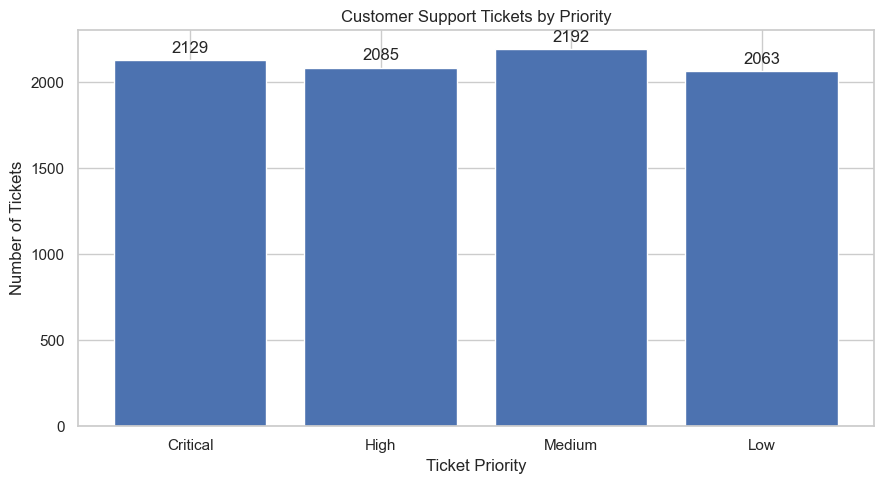

In [37]:
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(priority_summary.index, priority_summary["Ticket Count"])
ax.set_title("Customer Support Tickets by Priority")
ax.set_xlabel("Ticket Priority")
ax.set_ylabel("Number of Tickets")
ax.bar_label(bars, fmt="%.0f", padding=3)
plt.tight_layout()
plt.show()

### Actual result – Priority distribution
Medium priority is the largest group with **2,192 tickets (25.88%)**. Critical has **2,129 (25.14%)**, High has **2,085 (24.62%)**, and Low has **2,063 (24.36%)**. The priority categories are close in volume; Medium is the largest category, but it does not overwhelmingly dominate the workload.

### 4. Count tickets by communication channel and calculate percentages

### Description
Count tickets received through Email, Phone, Social media and Chat. Calculate each channel's percentage of the total 8,469 tickets.

This step identifies which communication channels receive the largest number of support tickets.

In [38]:
channel_order = ["Email", "Phone", "Social media", "Chat"]

channel_summary = (
    df_clean["Ticket Channel"]
    .value_counts()
    .reindex(channel_order, fill_value=0)
    .rename_axis("Ticket Channel")
    .to_frame("Ticket Count")
)
channel_summary["Percentage"] = (
    channel_summary["Ticket Count"] / total_tickets * 100
).round(2)

display(channel_summary)
print("Total channel count:", int(channel_summary["Ticket Count"].sum()))

,Ticket Count,Percentage
Ticket Channel,,
Email,2143,25.30
Phone,2132,25.17
Social media,2121,25.04
Chat,2073,24.48


Total channel count: 8469


### 5. Visualise the channel distribution

### Description
Create a horizontal bar chart comparing ticket volume across the four communication channels. The chart includes a clear title, axis labels and count labels.

### Interpretation
The chart shows whether one communication channel carries a noticeably larger workload or whether tickets are spread evenly across channels.

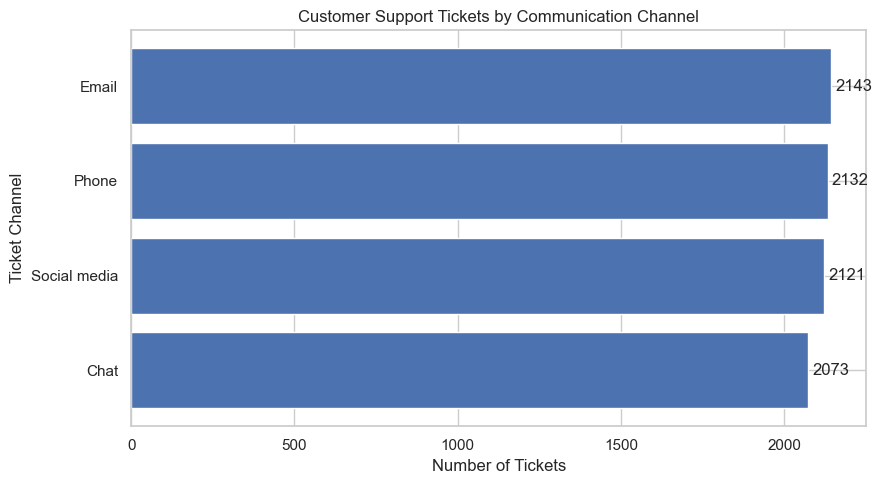

In [39]:
fig, ax = plt.subplots(figsize=(9, 5))
channel_plot = channel_summary.sort_values("Ticket Count")
bars = ax.barh(channel_plot.index, channel_plot["Ticket Count"])
ax.set_title("Customer Support Tickets by Communication Channel")
ax.set_xlabel("Number of Tickets")
ax.set_ylabel("Ticket Channel")
ax.bar_label(bars, fmt="%.0f", padding=3)
plt.tight_layout()
plt.show()

### Actual result – Channel distribution
Email has the highest volume with **2,143 tickets (25.30%)**. Phone has **2,132 (25.17%)**, Social media has **2,121 (25.04%)**, and Chat has **2,073 (24.48%)**. The difference between the largest and smallest channel is only 70 tickets, so the overall channel workload is distributed fairly evenly.

### 6. Compare status distribution across priority levels

### Description
Use `pd.crosstab()` to count Open, Pending Customer Response and Closed tickets within each priority category.

Then calculate row percentages. A row percentage answers: “Out of all tickets with this priority, what percentage is Open, Pending or Closed?” This is more useful than comparing raw counts alone when group sizes differ.

In [40]:
status_order = ["Open", "Pending Customer Response", "Closed"]

priority_status_counts = pd.crosstab(
    df_clean["Ticket Priority"], df_clean["Ticket Status"]
).reindex(index=priority_order, columns=status_order, fill_value=0)

priority_status_percentages = (
    priority_status_counts.div(priority_status_counts.sum(axis=1), axis=0) * 100
).round(2)

print("Priority vs Status – ticket counts")
display(priority_status_counts)
print("Priority vs Status – percentage within each priority")
display(priority_status_percentages)

Priority vs Status – ticket counts


Ticket Status,Open,Pending Customer Response,Closed
Ticket Priority,,,
Critical,692,711,726
High,704,676,705
Medium,727,771,694
Low,696,723,644


Priority vs Status – percentage within each priority


Ticket Status,Open,Pending Customer Response,Closed
Ticket Priority,,,
Critical,32.50,33.40,34.10
High,33.76,32.42,33.81
Medium,33.17,35.17,31.66
Low,33.74,35.05,31.22


### 7. Visualise status counts across priority levels

### Description
Create a stacked bar chart showing the count of Open, Pending Customer Response and Closed tickets for each priority. This makes it possible to compare both total workload and status composition across priorities.

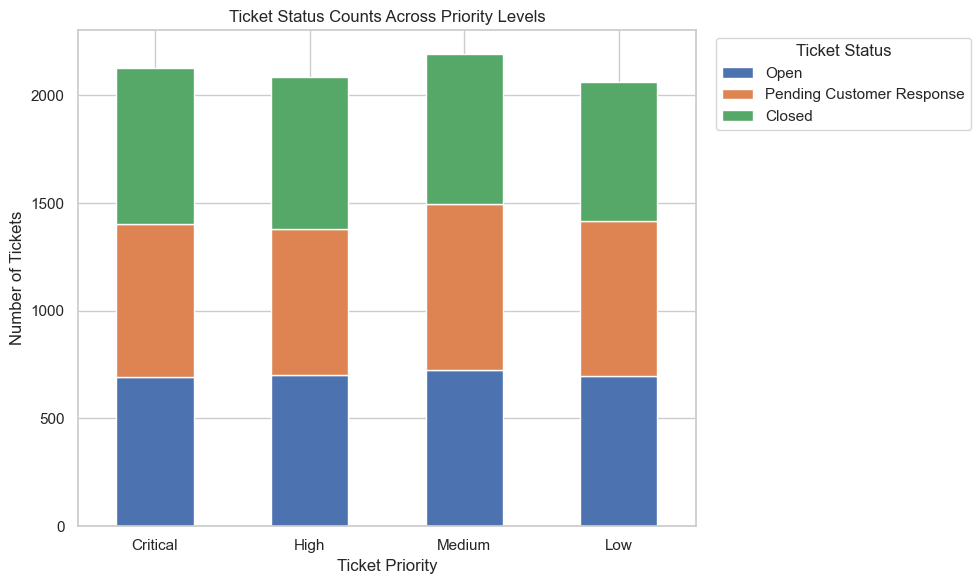

In [41]:
ax = priority_status_counts.plot(
    kind="bar", stacked=True, figsize=(10, 6)
)
ax.set_title("Ticket Status Counts Across Priority Levels")
ax.set_xlabel("Ticket Priority")
ax.set_ylabel("Number of Tickets")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Ticket Status", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Interpretation – Priority and status
Medium has the largest total priority workload (**2,192 tickets**) and also the largest combined Open/Pending count (**1,498**). Critical has the smallest Open/Pending share among priority groups. The table should be used to compare both the number of unresolved-status tickets and their percentage within each priority.

### 8. Compare status distribution across communication channels

### Description
Use another cross-tabulation to count Open, Pending Customer Response and Closed tickets within Email, Phone, Social media and Chat. Calculate row percentages to compare status mix within each channel.

In [42]:
channel_status_counts = pd.crosstab(
    df_clean["Ticket Channel"], df_clean["Ticket Status"]
).reindex(index=channel_order, columns=status_order, fill_value=0)

channel_status_percentages = (
    channel_status_counts.div(channel_status_counts.sum(axis=1), axis=0) * 100
).round(2)

print("Channel vs Status – ticket counts")
display(channel_status_counts)
print("Channel vs Status – percentage within each channel")
display(channel_status_percentages)

Channel vs Status – ticket counts


Ticket Status,Open,Pending Customer Response,Closed
Ticket Channel,,,
Email,701,722,720
Phone,736,705,691
Social media,697,740,684
Chat,685,714,674


Channel vs Status – percentage within each channel


Ticket Status,Open,Pending Customer Response,Closed
Ticket Channel,,,
Email,32.71,33.69,33.60
Phone,34.52,33.07,32.41
Social media,32.86,34.89,32.25
Chat,33.04,34.44,32.51


### 9. Visualise status distribution across channels

### Description
Create a stacked bar chart showing the number of Open, Pending Customer Response and Closed tickets for each channel. This chart supports a direct comparison of channel workload and status counts.

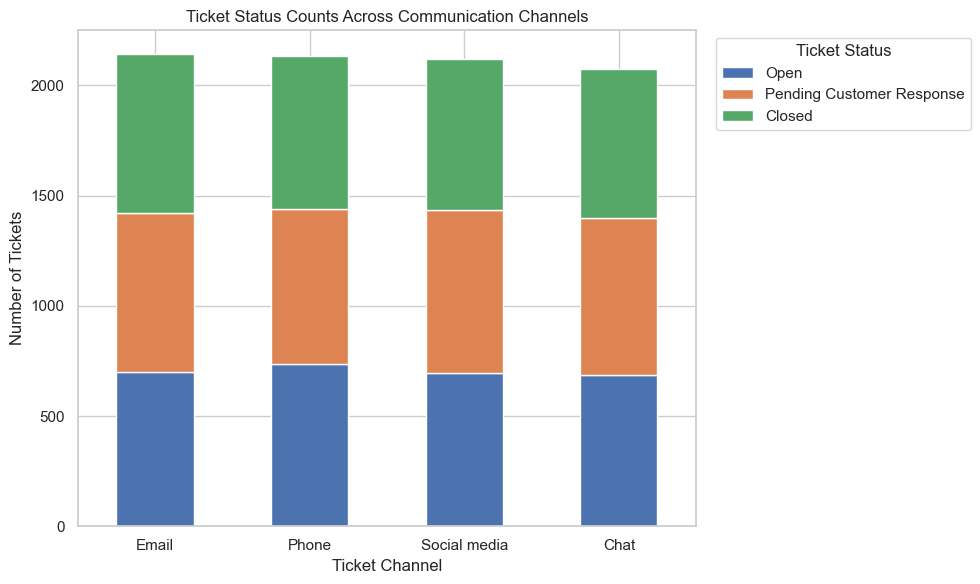

In [43]:
ax = channel_status_counts.plot(
    kind="bar", stacked=True, figsize=(10, 6)
)
ax.set_title("Ticket Status Counts Across Communication Channels")
ax.set_xlabel("Ticket Channel")
ax.set_ylabel("Number of Tickets")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Ticket Status", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Interpretation – Channel and status
Email has the largest total channel volume (**2,143 tickets**), while Phone has the largest combined Open/Pending count (**1,441**). Social media has the highest Open/Pending percentage among channels (**67.75%**). The counts and percentages describe the observed distribution and do not explain why tickets remain open or pending.

### 10. Compare priority and channel using cross-tabulation

### Description
Use `pd.crosstab()` to compare each priority category with each communication channel. This table shows the number of tickets in combinations such as Critical–Email or Medium–Phone.

A second table converts each combination into a percentage of all tickets. This helps identify high-volume priority-channel combinations.

In [44]:
priority_channel_counts = pd.crosstab(
    df_clean["Ticket Priority"], df_clean["Ticket Channel"]
).reindex(index=priority_order, columns=channel_order, fill_value=0)

priority_channel_percentages = (
    priority_channel_counts / total_tickets * 100
).round(2)

print("Priority vs Channel – ticket counts")
display(priority_channel_counts)
print("Priority vs Channel – percentage of all tickets")
display(priority_channel_percentages)

top_priority_channel = (
    priority_channel_counts.stack()
    .sort_values(ascending=False)
)
print("Highest-volume priority/channel combination:")
display(top_priority_channel.head(5).to_frame("Ticket Count"))

Priority vs Channel – ticket counts


Ticket Channel,Email,Phone,Social media,Chat
Ticket Priority,,,,
Critical,571,526,528,504
High,504,512,552,517
Medium,543,595,503,551
Low,525,499,538,501


Priority vs Channel – percentage of all tickets


Ticket Channel,Email,Phone,Social media,Chat
Ticket Priority,,,,
Critical,6.74,6.21,6.23,5.95
High,5.95,6.05,6.52,6.10
Medium,6.41,7.03,5.94,6.51
Low,6.20,5.89,6.35,5.92


Highest-volume priority/channel combination:


Ticket Count
Ticket Priority Ticket Channel              
Medium          Phone                    595
Critical        Email                    571
High            Social media             552
Medium          Chat                     551
                Email                    543

### 11. Visualise the priority-channel cross-tabulation

### Description
Create a heatmap using the priority-channel count table. Each cell represents the number of tickets in one priority and channel combination. The annotations show exact counts.

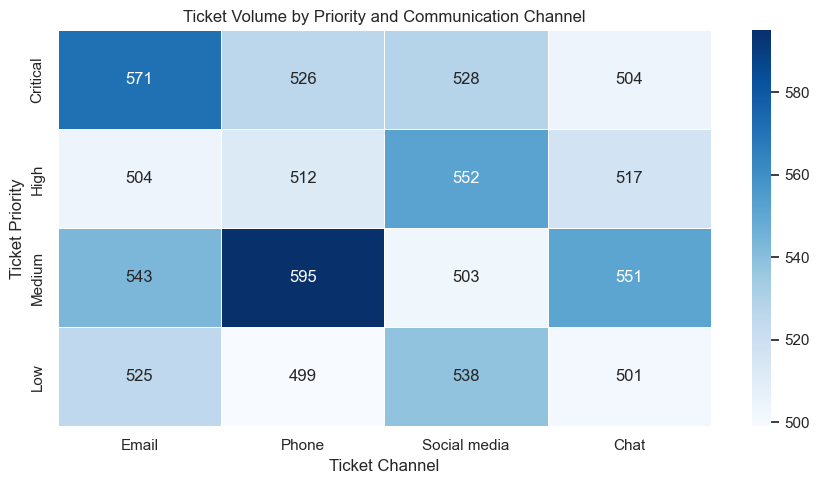

In [45]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(
    priority_channel_counts,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
    ax=ax
)
ax.set_title("Ticket Volume by Priority and Communication Channel")
ax.set_xlabel("Ticket Channel")
ax.set_ylabel("Ticket Priority")
plt.tight_layout()
plt.show()

### Interpretation – Priority and channel combination
The highest-volume combination is **Medium priority received through Phone**, with **595 tickets**. The next largest combinations include Critical–Email (**571**) and High–Social media (**552**). These combinations are useful workload hotspots for further operational review.

### 12. Identify high-volume groups and Open/Pending share

### Description
For each priority and channel, calculate:
- **Total Tickets:** all tickets in that group.
- **Open/Pending Tickets:** tickets with status Open or Pending Customer Response.
- **Open/Pending Percentage:** Open/Pending count divided by the group's total count, multiplied by 100.

This step identifies both the size of a group and the share of its tickets that are not Closed. Counts and percentages are reported together, as required by the team plan.

In [46]:
# Work on a separate copy so the shared df_clean keeps its 14 analytical columns.
member3_df = df_clean.assign(
    Open_Pending_Flag=df_clean["Ticket Status"].isin(
        ["Open", "Pending Customer Response"]
    )
)

priority_workload = (
    member3_df.groupby("Ticket Priority")
    .agg(
        Total_Tickets=("Ticket ID", "count"),
        Open_Pending_Tickets=("Open_Pending_Flag", "sum")
    )
    .reindex(priority_order)
)
priority_workload["Open_Pending_Percentage"] = (
    priority_workload["Open_Pending_Tickets"] /
    priority_workload["Total_Tickets"] * 100
).round(2)

channel_workload = (
    member3_df.groupby("Ticket Channel")
    .agg(
        Total_Tickets=("Ticket ID", "count"),
        Open_Pending_Tickets=("Open_Pending_Flag", "sum")
    )
    .reindex(channel_order)
)
channel_workload["Open_Pending_Percentage"] = (
    channel_workload["Open_Pending_Tickets"] /
    channel_workload["Total_Tickets"] * 100
).round(2)

print("Priority workload and Open/Pending share")
display(priority_workload)
print("Channel workload and Open/Pending share")
display(channel_workload)

Priority workload and Open/Pending share


,Total_Tickets,Open_Pending_Tickets,Open_Pending_Percentage
Ticket Priority,,,
Critical,2129,1403,65.90
High,2085,1380,66.19
Medium,2192,1498,68.34
Low,2063,1419,68.78


Channel workload and Open/Pending share


,Total_Tickets,Open_Pending_Tickets,Open_Pending_Percentage
Ticket Channel,,,
Email,2143,1423,66.40
Phone,2132,1441,67.59
Social media,2121,1437,67.75
Chat,2073,1399,67.49


### 13. Find priority-channel combinations with high volume and high Open/Pending share

### Description
Use `groupby()` on both `Ticket Priority` and `Ticket Channel`. For each combination, calculate total tickets, Open/Pending tickets and Open/Pending percentage.

This more detailed comparison can reveal combinations with a large workload or a high Open/Pending share. A percentage based on a small group should always be interpreted with its count.

In [47]:
priority_channel_workload = (
    member3_df
    .groupby(["Ticket Priority", "Ticket Channel"])
    .agg(
        Total_Tickets=("Ticket ID", "count"),
        Open_Pending_Tickets=("Open_Pending_Flag", "sum")
    )
)

priority_channel_workload["Open_Pending_Percentage"] = (
    priority_channel_workload["Open_Pending_Tickets"] /
    priority_channel_workload["Total_Tickets"] * 100
).round(2)

print("Priority/channel combinations sorted by ticket volume")
display(priority_channel_workload.sort_values("Total_Tickets", ascending=False))

print("Five combinations with the highest Open/Pending percentage")
display(
    priority_channel_workload
    .sort_values("Open_Pending_Percentage", ascending=False)
    .head(5)
)

Priority/channel combinations sorted by ticket volume


Total_Tickets  Open_Pending_Tickets  \
Ticket Priority Ticket Channel                                        
Medium          Phone                     595                   403   
Critical        Email                     571                   382   
High            Social media              552                   382   
Medium          Chat                      551                   388   
                Email                     543                   360   
Low             Social media              538                   363   
Critical        Social media              528                   345   
                Phone                     526                   337   
Low             Email                     525                   351   
High            Chat                      517                   328   
                Phone                     512                   340   
Critical        Chat                      504                   339   
High            Email                     504                   330   
Medium          Social media              503                   347   
Low             Chat                      501                   344   
                Phone                     499                   361   

                                Open_Pending_Percentage  
Ticket Priority Ticket Channel                           
Medium          Phone                             67.73  
Critical        Email                             66.90  
High            Social media                      69.20  
Medium          Chat                              70.42  
                Email                             66.30  
Low             Social media                      67.47  
Critical        Social media                      65.34  
                Phone                             64.07  
Low             Email                             66.86  
High            Chat                              63.44  
                Phone                             66.41  
Critical        Chat                              67.26  
High            Email                             65.48  
Medium          Social media                      68.99  
Low             Chat                              68.66  
                Phone                             72.34

Five combinations with the highest Open/Pending percentage


,,Total_Tickets,Open_Pending_Tickets,Open_Pending_Percentage
Ticket Priority,Ticket Channel,,,
Low,Phone,499,361,72.34
Medium,Chat,551,388,70.42
High,Social media,552,382,69.20
Medium,Social media,503,347,68.99
Low,Chat,501,344,68.66


### 14. Visualise Open/Pending percentages by priority and channel

### Description
Create two bar charts: one for priority and one for channel. The y-axis shows the percentage of tickets in Open or Pending Customer Response status. This allows the highest unresolved-status shares to be identified quickly.

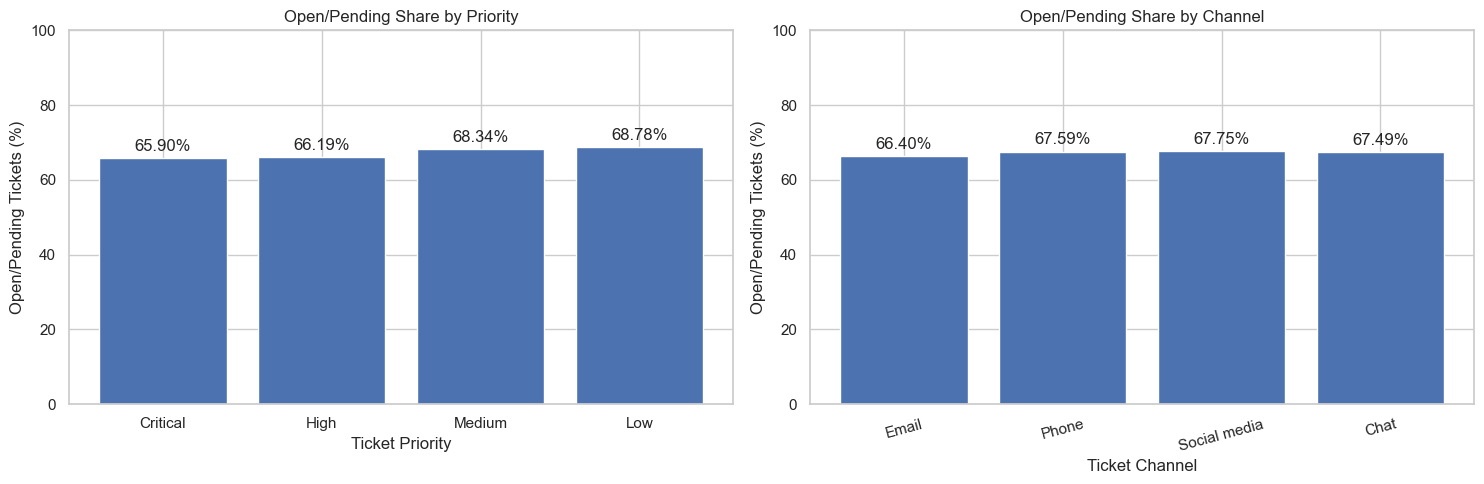

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

bars1 = axes[0].bar(
    priority_workload.index,
    priority_workload["Open_Pending_Percentage"]
)
axes[0].set_title("Open/Pending Share by Priority")
axes[0].set_xlabel("Ticket Priority")
axes[0].set_ylabel("Open/Pending Tickets (%)")
axes[0].set_ylim(0, 100)
axes[0].bar_label(bars1, fmt="%.2f%%", padding=3)

bars2 = axes[1].bar(
    channel_workload.index,
    channel_workload["Open_Pending_Percentage"]
)
axes[1].set_title("Open/Pending Share by Channel")
axes[1].set_xlabel("Ticket Channel")
axes[1].set_ylabel("Open/Pending Tickets (%)")
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis="x", rotation=15)
axes[1].bar_label(bars2, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

### Interpretation – Open/Pending share
Low priority has the highest Open/Pending share among priority groups (**68.78%; 1,419 of 2,063 tickets**). Social media has the highest Open/Pending share among channels (**67.75%; 1,437 of 2,121 tickets**). These groups merit further investigation, but the analysis alone does not establish the cause of their status distribution.

### 15. Summarise the verified findings

### Description
Generate a concise set of findings using the tables created above. This summary uses actual counts and percentages from the supplied CSV and can be shared with Member 5 for the final presentation.

In [49]:
top_priority = priority_summary["Ticket Count"].idxmax()
top_channel = channel_summary["Ticket Count"].idxmax()
top_combo = priority_channel_counts.stack().idxmax()
highest_priority_open_share = priority_workload["Open_Pending_Percentage"].idxmax()
highest_channel_open_share = channel_workload["Open_Pending_Percentage"].idxmax()
highest_combo_open_share = priority_channel_workload["Open_Pending_Percentage"].idxmax()

print("========== MEMBER 3: KEY FINDINGS ==========")
print(f"Total tickets analysed: {total_tickets:,}")
print(
    f"Highest priority volume: {top_priority} – "
    f"{priority_summary.loc[top_priority, 'Ticket Count']:,} tickets "
    f"({priority_summary.loc[top_priority, 'Percentage']:.2f}%)."
)
print(
    f"Highest channel volume: {top_channel} – "
    f"{channel_summary.loc[top_channel, 'Ticket Count']:,} tickets "
    f"({channel_summary.loc[top_channel, 'Percentage']:.2f}%)."
)
print(
    f"Highest-volume priority/channel combination: {top_combo[0]} + {top_combo[1]} – "
    f"{priority_channel_counts.loc[top_combo[0], top_combo[1]]:,} tickets."
)
print(
    f"Highest Open/Pending share by priority: {highest_priority_open_share} – "
    f"{priority_workload.loc[highest_priority_open_share, 'Open_Pending_Tickets']:,} of "
    f"{priority_workload.loc[highest_priority_open_share, 'Total_Tickets']:,} "
    f"({priority_workload.loc[highest_priority_open_share, 'Open_Pending_Percentage']:.2f}%)."
)
print(
    f"Highest Open/Pending share by channel: {highest_channel_open_share} – "
    f"{channel_workload.loc[highest_channel_open_share, 'Open_Pending_Tickets']:,} of "
    f"{channel_workload.loc[highest_channel_open_share, 'Total_Tickets']:,} "
    f"({channel_workload.loc[highest_channel_open_share, 'Open_Pending_Percentage']:.2f}%)."
)
print(
    f"Highest Open/Pending share among priority/channel combinations: "
    f"{highest_combo_open_share[0]} + {highest_combo_open_share[1]} – "
    f"{priority_channel_workload.loc[highest_combo_open_share, 'Open_Pending_Tickets']:,} of "
    f"{priority_channel_workload.loc[highest_combo_open_share, 'Total_Tickets']:,} "
    f"({priority_channel_workload.loc[highest_combo_open_share, 'Open_Pending_Percentage']:.2f}%)."
)
print("============================================")

========== MEMBER 3: KEY FINDINGS ==========
Total tickets analysed: 8,469
Highest priority volume: Medium – 2,192 tickets (25.88%).
Highest channel volume: Email – 2,143 tickets (25.30%).
Highest-volume priority/channel combination: Medium + Phone – 595 tickets.
Highest Open/Pending share by priority: Low – 1,419 of 2,063 (68.78%).
Highest Open/Pending share by channel: Social media – 1,437 of 2,121 (67.75%).
Highest Open/Pending share among priority/channel combinations: Low + Phone – 361 of 499 (72.34%).


### 16. Export the Member 3 result tables

### Description
Save the priority summary, channel summary, status comparison tables, priority-channel cross-tabulation and workload tables as CSV files. These files can be shared with Member 5 for the dashboard and presentation.

The original customer-support CSV is not overwritten.

In [50]:
results_folder = "member3_results"
os.makedirs(results_folder, exist_ok=True)

result_tables = {
    "priority_summary.csv": priority_summary,
    "channel_summary.csv": channel_summary,
    "priority_status_counts.csv": priority_status_counts,
    "priority_status_percentages.csv": priority_status_percentages,
    "channel_status_counts.csv": channel_status_counts,
    "channel_status_percentages.csv": channel_status_percentages,
    "priority_channel_counts.csv": priority_channel_counts,
    "priority_channel_percentages.csv": priority_channel_percentages,
    "priority_workload_open_pending.csv": priority_workload,
    "channel_workload_open_pending.csv": channel_workload,
    "priority_channel_workload_open_pending.csv": priority_channel_workload
}

for filename, result_table in result_tables.items():
    result_table.to_csv(os.path.join(results_folder, filename))

print(f"{len(result_tables)} result tables saved in '{results_folder}'.")
print("The original CSV remains unchanged.")

11 result tables saved in 'member3_results'.
The original CSV remains unchanged.


### 17. Final conclusion

The Member 3 analysis examined **8,469 customer-support tickets** using the priority, channel and status fields. The work followed the Member 1 cleaning approach and used a separate analytical copy that excludes customer names, email addresses and ticket descriptions.

The priority analysis found that **Medium** had the highest ticket volume, with **2,192 tickets (25.88%)**. The channel analysis found that **Email** had the highest volume, with **2,143 tickets (25.30%)**. The largest priority-channel combination was **Medium priority through Phone**, with **595 tickets**.

The status comparisons showed that **Low priority** had the highest Open/Pending share among priority groups: **1,419 of 2,063 tickets (68.78%)**. Among channels, **Social media** had the highest Open/Pending share: **1,437 of 2,121 tickets (67.75%)**. In the combined priority-channel comparison, **Low priority through Phone** had the highest Open/Pending share: **361 of 499 tickets (72.34%)**.

These results identify workload concentrations and groups that may deserve further operational investigation. They do not prove why tickets remain Open or Pending, and they do not establish that a particular priority or channel causes delays.



### Member 4 – Response, Resolution and Satisfaction Analyst

### Introduction

This section examines the availability and quality of response-time, resolution and customer-satisfaction information. It uses the cleaned analytical dataset prepared by Member 1 when available. The analysis reports only values supported by the supplied data and does not calculate elapsed durations from timestamps that do not establish a valid start/end pair.

**Member 4 objective:** provide a response/resolution coverage summary, satisfaction analysis, one customer-age or product comparison, and clear limitations.

In [51]:
# MEMBER 4 – RESPONSE, RESOLUTION AND SATISFACTION ANALYSIS
# Use Member 1's cleaned DataFrame when it is already available.
# Otherwise, load the cleaned CSV; if that file is not present, load the supplied raw CSV.
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

if "df_clean" not in globals():
    if os.path.exists("cleaned_customer_support_tickets.csv"):
        df_clean = pd.read_csv("cleaned_customer_support_tickets.csv")
    else:
        df_clean = pd.read_csv("customer_support_tickets.csv")

# Work on a separate copy so the shared analytical dataset is not modified.
member4_df = df_clean.copy()

required_columns = [
    "First Response Time",
    "Time to Resolution",
    "Resolution",
    "Customer Satisfaction Rating",
    "Customer Age",
    "Product Purchased",
    "Ticket Type",
    "Ticket Priority",
    "Ticket Channel",
    "Ticket Status"
]

missing_columns = [column for column in required_columns if column not in member4_df.columns]
if missing_columns:
    raise KeyError(f"Required Member 4 columns are missing: {missing_columns}")

print("Member 4 dataset loaded successfully.")
print("Dataset dimensions:", member4_df.shape)
print("Required analysis columns are available.")

Member 4 dataset loaded successfully.
Dataset dimensions: (8469, 14)
Required analysis columns are available.


### 1 – Check response and resolution field coverage

### Description

Count the available and missing values in `First Response Time`, `Time to Resolution` and `Resolution`. This establishes how much information is available before attempting any further analysis. Missing values are kept as missing; they are not replaced with zero.

In [52]:
# Count available and missing values in the three response/resolution fields.
coverage_columns = [
    "First Response Time",
    "Time to Resolution",
    "Resolution"
]

coverage_summary = pd.DataFrame({
    "Available Count": member4_df[coverage_columns].notna().sum(),
    "Missing Count": member4_df[coverage_columns].isna().sum(),
    "Available Percentage": (
        member4_df[coverage_columns].notna().mean() * 100
    ).round(2)
})

display(coverage_summary)
print("Total tickets examined:", len(member4_df))

,Available Count,Missing Count,Available Percentage
First Response Time,5650,2819,66.71
Time to Resolution,2769,5700,32.70
Resolution,2769,5700,32.70


Total tickets examined: 8469


### 2 – Validate timestamp values

### Description

Convert the two timestamp columns with `pd.to_datetime(errors='coerce')` in separate analysis-only series. Count valid timestamps, missing values and non-missing values that could not be parsed. The original columns are not overwritten. These fields are treated as timestamp values only; this step does not calculate response or resolution duration.

In [53]:
# Validate timestamp formats without overwriting the original columns.
timestamp_columns = ["First Response Time", "Time to Resolution"]
timestamp_validation = []

for column in timestamp_columns:
    parsed_values = pd.to_datetime(member4_df[column], errors="coerce")
    original_present = member4_df[column].notna()

    timestamp_validation.append({
        "Field": column,
        "Valid Timestamps": int(parsed_values.notna().sum()),
        "Missing Values": int(member4_df[column].isna().sum()),
        "Invalid Non-missing Values": int((original_present & parsed_values.isna()).sum())
    })

timestamp_validation = pd.DataFrame(timestamp_validation).set_index("Field")
display(timestamp_validation)

,Valid Timestamps,Missing Values,Invalid Non-missing Values
Field,,,
First Response Time,5650,2819,0
Time to Resolution,2769,5700,0


### 3 – Visualise response and resolution information coverage

### Description

Create a grouped bar chart showing available and missing values for the three fields. The chart makes the coverage gaps easy to compare. Counts are shown rather than treating missing values as zero-duration events.

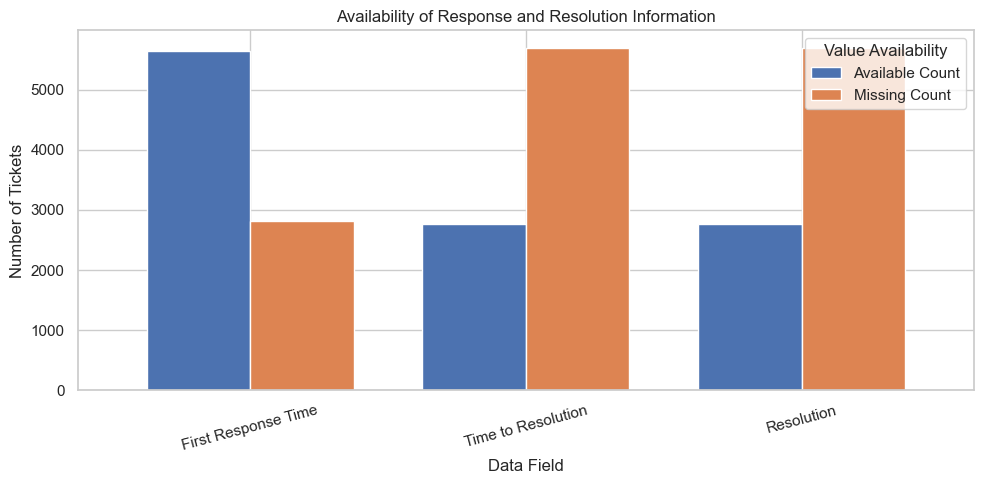

In [54]:
# Plot available and missing values for response and resolution fields.
coverage_plot = coverage_summary[["Available Count", "Missing Count"]]

ax = coverage_plot.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75
)
ax.set_title("Availability of Response and Resolution Information")
ax.set_xlabel("Data Field")
ax.set_ylabel("Number of Tickets")
ax.legend(title="Value Availability")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

### Output interpretation – Response and resolution coverage

The dataset contains **8,469 tickets**. `First Response Time` is present for **5,650 tickets (66.71%)** and missing for **2,819**. `Time to Resolution` and `Resolution` are each present for **2,769 tickets (32.70%)** and missing for **5,700**. These figures describe field coverage only; they do not measure elapsed time.

### 4 – Analyse customer satisfaction rating coverage

### Description

Check the number of valid and missing satisfaction ratings. For this analysis, valid ratings are numeric values from 1 to 5, matching the five rating values present in the supplied dataset. Missing or out-of-range values are excluded from rating calculations and are never replaced with zero.

In [55]:
# Convert ratings safely and retain only valid values from 1 to 5.
member4_df["Satisfaction Numeric"] = pd.to_numeric(
    member4_df["Customer Satisfaction Rating"],
    errors="coerce"
)

valid_rating_mask = member4_df["Satisfaction Numeric"].between(1, 5)
valid_ratings = member4_df.loc[valid_rating_mask].copy()

rating_coverage = pd.DataFrame({
    "Measure": [
        "Total tickets",
        "Valid satisfaction ratings",
        "Missing or invalid ratings"
    ],
    "Count": [
        len(member4_df),
        int(valid_rating_mask.sum()),
        int((~valid_rating_mask).sum())
    ]
})
rating_coverage["Percentage"] = (
    rating_coverage["Count"] / len(member4_df) * 100
).round(2)

display(rating_coverage)

print("Average valid satisfaction rating:",
      round(valid_ratings["Satisfaction Numeric"].mean(), 2))
print("Rating scale observed:",
      sorted(valid_ratings["Satisfaction Numeric"].dropna().unique().tolist()))

,Measure,Count,Percentage
0,Total tickets,8469,100.0
1,Valid satisfaction ratings,2769,32.7
2,Missing or invalid ratings,5700,67.3


Average valid satisfaction rating: 2.99
Rating scale observed: [1.0, 2.0, 3.0, 4.0, 5.0]


### 5 – Visualise customer satisfaction ratings

### Description

Count valid responses for each rating value from 1 to 5 and display them in a bar chart. The chart describes the distribution of recorded ratings only; it does not represent the opinions of tickets with missing ratings.

,Number of Responses
Rating,
1,553
2,549
3,580
4,543
5,544


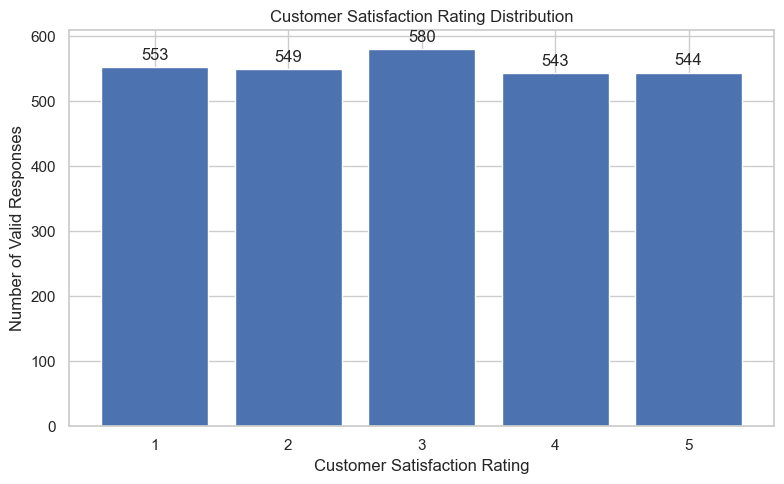

In [56]:
# Count valid ratings and plot the rating distribution.
rating_order = [1, 2, 3, 4, 5]
rating_counts = (
    valid_ratings["Satisfaction Numeric"]
    .value_counts()
    .reindex(rating_order, fill_value=0)
    .sort_index()
)

display(rating_counts.rename_axis("Rating").to_frame("Number of Responses"))

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(rating_counts.index.astype(str), rating_counts.values)
ax.set_title("Customer Satisfaction Rating Distribution")
ax.set_xlabel("Customer Satisfaction Rating")
ax.set_ylabel("Number of Valid Responses")
ax.bar_label(bars, padding=3)
plt.tight_layout()
plt.show()

### Output interpretation – Satisfaction rating distribution

There are **2,769 valid satisfaction ratings (32.70% of all tickets)**, while **5,700 tickets (67.30%)** have no valid rating. The average among recorded ratings is **2.99 out of 5**. Rating 3 is the most frequent response (**580 ratings**). The missing ratings are excluded from the average and chart.

### 6 – Compare satisfaction across ticket type and priority

### Description

Group valid ratings by ticket type and ticket priority. Calculate the sample count and average rating for each group. Showing `n` beside the mean helps the reader understand how many valid ratings support each comparison. These are descriptive comparisons and do not establish the cause of a rating difference.

In [57]:
# Compare average satisfaction by ticket type and priority.
satisfaction_by_type = (
    valid_ratings.groupby("Ticket Type")["Satisfaction Numeric"]
    .agg(Sample_Count="count", Average_Rating="mean")
    .sort_values("Average_Rating", ascending=False)
)
satisfaction_by_type["Average_Rating"] = satisfaction_by_type["Average_Rating"].round(2)

satisfaction_by_priority = (
    valid_ratings.groupby("Ticket Priority")["Satisfaction Numeric"]
    .agg(Sample_Count="count", Average_Rating="mean")
    .reindex(["Critical", "High", "Medium", "Low"])
)
satisfaction_by_priority["Average_Rating"] = satisfaction_by_priority["Average_Rating"].round(2)

print("Satisfaction by ticket type")
display(satisfaction_by_type)

print("Satisfaction by ticket priority")
display(satisfaction_by_priority)

Satisfaction by ticket type


,Sample_Count,Average_Rating
Ticket Type,,
Cancellation request,516,3.03
Billing inquiry,544,3.03
Product inquiry,533,3.02
Technical issue,580,2.96
Refund request,596,2.93


Satisfaction by ticket priority


,Sample_Count,Average_Rating
Ticket Priority,,
Critical,726,2.96
High,705,2.98
Medium,694,2.98
Low,644,3.05


### 7 – Visualise satisfaction by ticket type and priority

### Description

Create two labelled bar charts for the average valid satisfaction rating by ticket type and priority. The sample counts are added to the category labels so that each average is read together with its sample size.

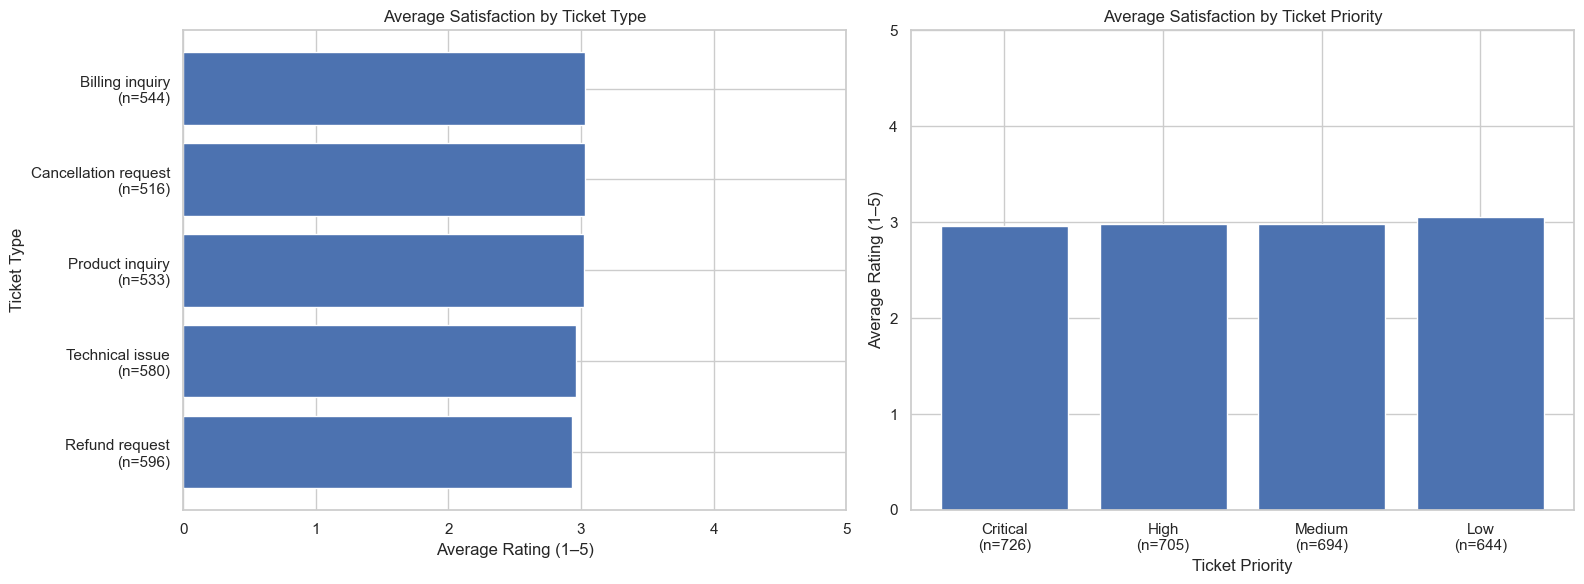

In [58]:
# Plot mean ratings by ticket type and priority, with sample counts in labels.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

type_plot = satisfaction_by_type.sort_values("Average_Rating")
type_labels = [
    f"{name}\n(n={int(satisfaction_by_type.loc[name, 'Sample_Count'])})"
    for name in type_plot.index
]
axes[0].barh(type_labels, type_plot["Average_Rating"])
axes[0].set_title("Average Satisfaction by Ticket Type")
axes[0].set_xlabel("Average Rating (1–5)")
axes[0].set_ylabel("Ticket Type")
axes[0].set_xlim(0, 5)

priority_plot = satisfaction_by_priority.dropna()
priority_labels = [
    f"{name}\n(n={int(priority_plot.loc[name, 'Sample_Count'])})"
    for name in priority_plot.index
]
axes[1].bar(priority_labels, priority_plot["Average_Rating"])
axes[1].set_title("Average Satisfaction by Ticket Priority")
axes[1].set_xlabel("Ticket Priority")
axes[1].set_ylabel("Average Rating (1–5)")
axes[1].set_ylim(0, 5)

plt.tight_layout()
plt.show()

### Output interpretation – Satisfaction by ticket type and priority

Among ticket types, Cancellation request (**3.03; n=516**) and Billing inquiry (**3.03; n=544**) show the same rounded average, with Cancellation request marginally ahead before rounding; Refund request is lowest (**2.93; n=596**). Among priority groups, Low has the highest average (**3.05; n=644**) and Critical the lowest (**2.96; n=726**). All averages are based only on tickets with valid satisfaction ratings; these descriptive differences are small and do not establish causes.

### 8 – Compare satisfaction across customer age groups

### Description

Complete the required customer-profile comparison by grouping customers into age bands. For each band, calculate the number of valid satisfaction ratings and the average rating. The age bands are used only to organise the descriptive comparison; they do not imply that age causes satisfaction.

In [59]:
# Create customer age bands and compare valid satisfaction ratings.
age_bins = [0, 24, 34, 44, 54, 100]
age_labels = ["18–24", "25–34", "35–44", "45–54", "55+"]

valid_ratings["Customer Age Group"] = pd.cut(
    valid_ratings["Customer Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

satisfaction_by_age = (
    valid_ratings.groupby("Customer Age Group", observed=False)["Satisfaction Numeric"]
    .agg(Sample_Count="count", Average_Rating="mean")
    .reindex(age_labels)
)
satisfaction_by_age["Average_Rating"] = satisfaction_by_age["Average_Rating"].round(2)

display(satisfaction_by_age)

,Sample_Count,Average_Rating
Customer Age Group,,
18–24,352,2.95
25–34,510,3.08
35–44,515,2.96
45–54,556,3.01
55+,836,2.96


### 9 – Visualise satisfaction by customer age group

### Description

Plot the average valid satisfaction rating for each age group. Include the sample count in each category label. This provides a direct comparison between customer age bands while making the available sample size visible.

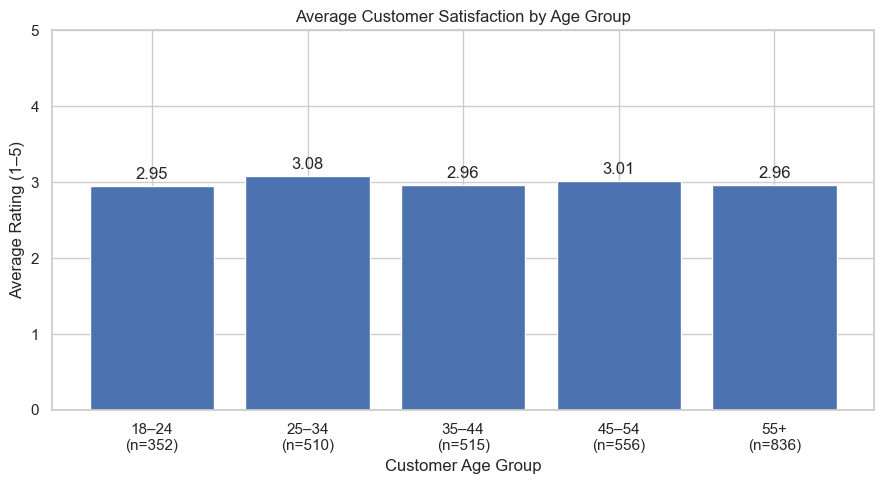

In [60]:
# Plot average satisfaction by customer age group with sample counts.
age_plot = satisfaction_by_age.dropna(subset=["Average_Rating"])

fig, ax = plt.subplots(figsize=(9, 5))
age_tick_labels = [
    f"{group}\n(n={int(age_plot.loc[group, 'Sample_Count'])})"
    for group in age_plot.index
]
bars = ax.bar(age_tick_labels, age_plot["Average_Rating"])
ax.set_title("Average Customer Satisfaction by Age Group")
ax.set_xlabel("Customer Age Group")
ax.set_ylabel("Average Rating (1–5)")
ax.set_ylim(0, 5)
ax.bar_label(bars, fmt="%.2f", padding=3)
plt.tight_layout()
plt.show()

### Output interpretation – Satisfaction by customer age group

The **25–34** age group has the highest average recorded rating (**3.08; n=510**). The **18–24** group has the lowest (**2.95; n=352**). The 55+ group has the largest valid sample (**n=836**) and an average of **2.96**. The comparison is descriptive and should be interpreted alongside the sample counts.

### 10 – Summarise Member 4 findings and limitations

### Description

Generate a compact summary using the calculated coverage and satisfaction tables. The summary reports the number of valid ratings and the highest and lowest average-rating groups, including their sample counts. It also records the main analytical limitation: the supplied timestamp fields do not provide a documented start/end pair or an explicit elapsed-duration field, so response duration, resolution duration and SLA performance are not calculated.

In [61]:
# Print verified Member 4 findings and analytical limitations.
total_records = len(member4_df)
valid_rating_count = int(valid_rating_mask.sum())
missing_rating_count = total_records - valid_rating_count

print("MEMBER 4 – VERIFIED FINDINGS")
print("--------------------------------")
print(f"Total tickets examined: {total_records:,}")
print(f"Valid satisfaction ratings: {valid_rating_count:,} "
      f"({valid_rating_count / total_records * 100:.2f}%)")
print(f"Missing or invalid satisfaction ratings: {missing_rating_count:,} "
      f"({missing_rating_count / total_records * 100:.2f}%)")
print(f"Average valid satisfaction rating: "
      f"{valid_ratings['Satisfaction Numeric'].mean():.2f} out of 5")

if not satisfaction_by_age.dropna(subset=["Average_Rating"]).empty:
    age_valid = satisfaction_by_age.dropna(subset=["Average_Rating"])
    highest_age = age_valid["Average_Rating"].idxmax()
    lowest_age = age_valid["Average_Rating"].idxmin()
    print(f"Highest age-group average: {highest_age} "
          f"({age_valid.loc[highest_age, 'Average_Rating']:.2f}; "
          f"n={int(age_valid.loc[highest_age, 'Sample_Count'])})")
    print(f"Lowest age-group average: {lowest_age} "
          f"({age_valid.loc[lowest_age, 'Average_Rating']:.2f}; "
          f"n={int(age_valid.loc[lowest_age, 'Sample_Count'])})")

print("\nDATA LIMITATIONS")
print("- Missing satisfaction ratings were excluded, not treated as zero.")
print("- Timestamp presence does not by itself establish elapsed response or resolution duration.")
print("- No response duration, resolution duration or SLA performance was calculated.")
print("- Group differences are descriptive and do not prove cause and effect.")

MEMBER 4 – VERIFIED FINDINGS
--------------------------------
Total tickets examined: 8,469
Valid satisfaction ratings: 2,769 (32.70%)
Missing or invalid satisfaction ratings: 5,700 (67.30%)
Average valid satisfaction rating: 2.99 out of 5
Highest age-group average: 25–34 (3.08; n=510)
Lowest age-group average: 18–24 (2.95; n=352)

DATA LIMITATIONS
- Missing satisfaction ratings were excluded, not treated as zero.
- Timestamp presence does not by itself establish elapsed response or resolution duration.
- No response duration, resolution duration or SLA performance was calculated.
- Group differences are descriptive and do not prove cause and effect.


### Output interpretation – Overall Member 4 findings

The supplied data provides a First Response Time timestamp for 5,650 tickets and Time to Resolution timestamp for 2,769 tickets. Both timestamp fields have no non-missing values that failed parsing in this dataset. However, timestamp presence alone does not provide a documented start/end pair or an explicit elapsed duration. Therefore, response duration, resolution duration and SLA performance are not calculated.

### Member 4 – Final conclusion

The Member 4 analysis checks the coverage and validity of response and resolution information and evaluates customer satisfaction only for valid recorded ratings. It also compares satisfaction across ticket categories and customer age groups, with sample counts shown alongside averages. The results should be interpreted as descriptive findings. Because the dataset does not document valid start/end pairs or an explicit elapsed-duration measure, response-time, resolution-time and SLA calculations are not supported by the supplied fields.

### MEMBER 5 – INTEGRATION, DASHBOARD AND PRESENTATION

### Description

Member 5 combines the verified outputs of Members 1–4 into one executive view. This section summarises the overall ticket workload, status distribution, leading ticket categories, priority and channel patterns, and the availability of customer satisfaction ratings.

The dashboard uses the cleaned analytical dataset and calculates its summary values directly from the data. It does not create new predictions or claim that a chart proves the cause of a pattern. Customer names, email addresses and ticket descriptions are not displayed.

**Expected output:** an integrated KPI summary, dashboard charts, key findings, practical investigation recommendations and exported files for the final presentation.


### 1 – Prepare the integrated analytical dataset

### Description

Use the cleaned dataset created by Member 1 when it is available. If it is not available in the current notebook session, load the supplied CSV and create a separate working copy. Check that the columns needed for the integrated dashboard are present. The raw CSV is never overwritten.


In [62]:
# Prepare a separate DataFrame for Member 5 integration.
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

if "df_clean" in globals():
    member5_df = df_clean.copy()
elif os.path.exists("cleaned_customer_support_tickets.csv"):
    member5_df = pd.read_csv("cleaned_customer_support_tickets.csv")
else:
    member5_df = pd.read_csv("customer_support_tickets.csv")

dashboard_columns = [
    "Ticket Status", "Ticket Type", "Ticket Subject",
    "Ticket Priority", "Ticket Channel",
    "Customer Satisfaction Rating"
]
missing_dashboard_columns = [
    column for column in dashboard_columns
    if column not in member5_df.columns
]

if missing_dashboard_columns:
    raise ValueError(
        "The dashboard cannot run because these columns are missing: "
        + ", ".join(missing_dashboard_columns)
    )

# Exclude direct personal identifiers and free-text descriptions from this analysis copy.
private_columns = [
    "Customer Name", "Customer Email", "Ticket Description"
]
member5_df = member5_df.drop(
    columns=[column for column in private_columns if column in member5_df.columns]
)

print("Member 5 dataset shape:", member5_df.shape)
print("Dashboard columns are available.")
display(member5_df[dashboard_columns].head())


Member 5 dataset shape: (8469, 14)
Dashboard columns are available.


,Ticket Status,Ticket Type,Ticket Subject,Ticket Priority,Ticket Channel,Customer Satisfaction Rating
0,Pending Customer Response,Technical issue,Product setup,Critical,Social media,NaN
1,Pending Customer Response,Technical issue,Peripheral compatibility,Critical,Chat,NaN
2,Closed,Technical issue,Network problem,Low,Social media,3.0
3,Closed,Billing inquiry,Account access,Low,Social media,3.0
4,Closed,Billing inquiry,Data loss,Low,Email,1.0


### 2 – Calculate executive summary metrics

### Description

Calculate the total number of tickets, ticket status counts and percentages, most frequent ticket type and subject, most frequent priority and channel, and valid satisfaction-rating coverage. Every percentage is calculated using the relevant ticket count as its denominator. Missing or invalid satisfaction ratings are not treated as zero.


In [63]:
# Calculate the overall ticket and category summaries.
total_tickets_m5 = len(member5_df)

status_summary_m5 = (
    member5_df["Ticket Status"].fillna("Missing")
    .value_counts()
    .rename_axis("Ticket Status")
    .to_frame("Ticket Count")
)
status_summary_m5["Percentage"] = (
    status_summary_m5["Ticket Count"] / total_tickets_m5 * 100
).round(2)

def top_category_summary(data, column):
    counts = data[column].fillna("Missing").value_counts()
    if counts.empty:
        return "Not available", 0, 0.0
    category = counts.index[0]
    count = int(counts.iloc[0])
    percentage = count / len(data) * 100 if len(data) else 0
    return str(category), count, round(percentage, 2)

top_type_m5 = top_category_summary(member5_df, "Ticket Type")
top_subject_m5 = top_category_summary(member5_df, "Ticket Subject")
top_priority_m5 = top_category_summary(member5_df, "Ticket Priority")
top_channel_m5 = top_category_summary(member5_df, "Ticket Channel")

rating_numeric_m5 = pd.to_numeric(
    member5_df["Customer Satisfaction Rating"], errors="coerce"
)
valid_rating_mask_m5 = rating_numeric_m5.between(1, 5)
valid_rating_count_m5 = int(valid_rating_mask_m5.sum())
rating_coverage_pct_m5 = (
    valid_rating_count_m5 / total_tickets_m5 * 100
    if total_tickets_m5 else 0
)
average_rating_m5 = (
    round(float(rating_numeric_m5[valid_rating_mask_m5].mean()), 2)
    if valid_rating_count_m5 else np.nan
)

executive_summary_m5 = pd.DataFrame([
    ["Total tickets", total_tickets_m5, 100.0],
    ["Valid satisfaction ratings", valid_rating_count_m5, round(rating_coverage_pct_m5, 2)],
    ["Missing or invalid satisfaction ratings",
     total_tickets_m5 - valid_rating_count_m5,
     round(100 - rating_coverage_pct_m5, 2)]
], columns=["Measure", "Count", "Percentage"])

print("EXECUTIVE SUMMARY")
display(executive_summary_m5)
print("Most frequent ticket type:", top_type_m5)
print("Most frequent ticket subject:", top_subject_m5)
print("Most frequent priority:", top_priority_m5)
print("Most frequent channel:", top_channel_m5)
print("Average valid satisfaction rating:", average_rating_m5)
display(status_summary_m5)


EXECUTIVE SUMMARY


,Measure,Count,Percentage
0,Total tickets,8469,100.0
1,Valid satisfaction ratings,2769,32.7
2,Missing or invalid satisfaction ratings,5700,67.3


Most frequent ticket type: ('Refund request', 1752, 20.69)
Most frequent ticket subject: ('Refund request', 576, 6.8)
Most frequent priority: ('Medium', 2192, 25.88)
Most frequent channel: ('Email', 2143, 25.3)
Average valid satisfaction rating: 2.99


,Ticket Count,Percentage
Ticket Status,,
Pending Customer Response,2881,34.02
Open,2819,33.29
Closed,2769,32.70


### 3 – Create the integrated SUPPORT SCOPE dashboard

### Description

Create a single dashboard containing ticket status, ticket type, priority, channel and satisfaction information. The charts use counts or valid-rating values from the dataset. Titles, axis labels and sample counts make the results easier to interpret during the presentation.


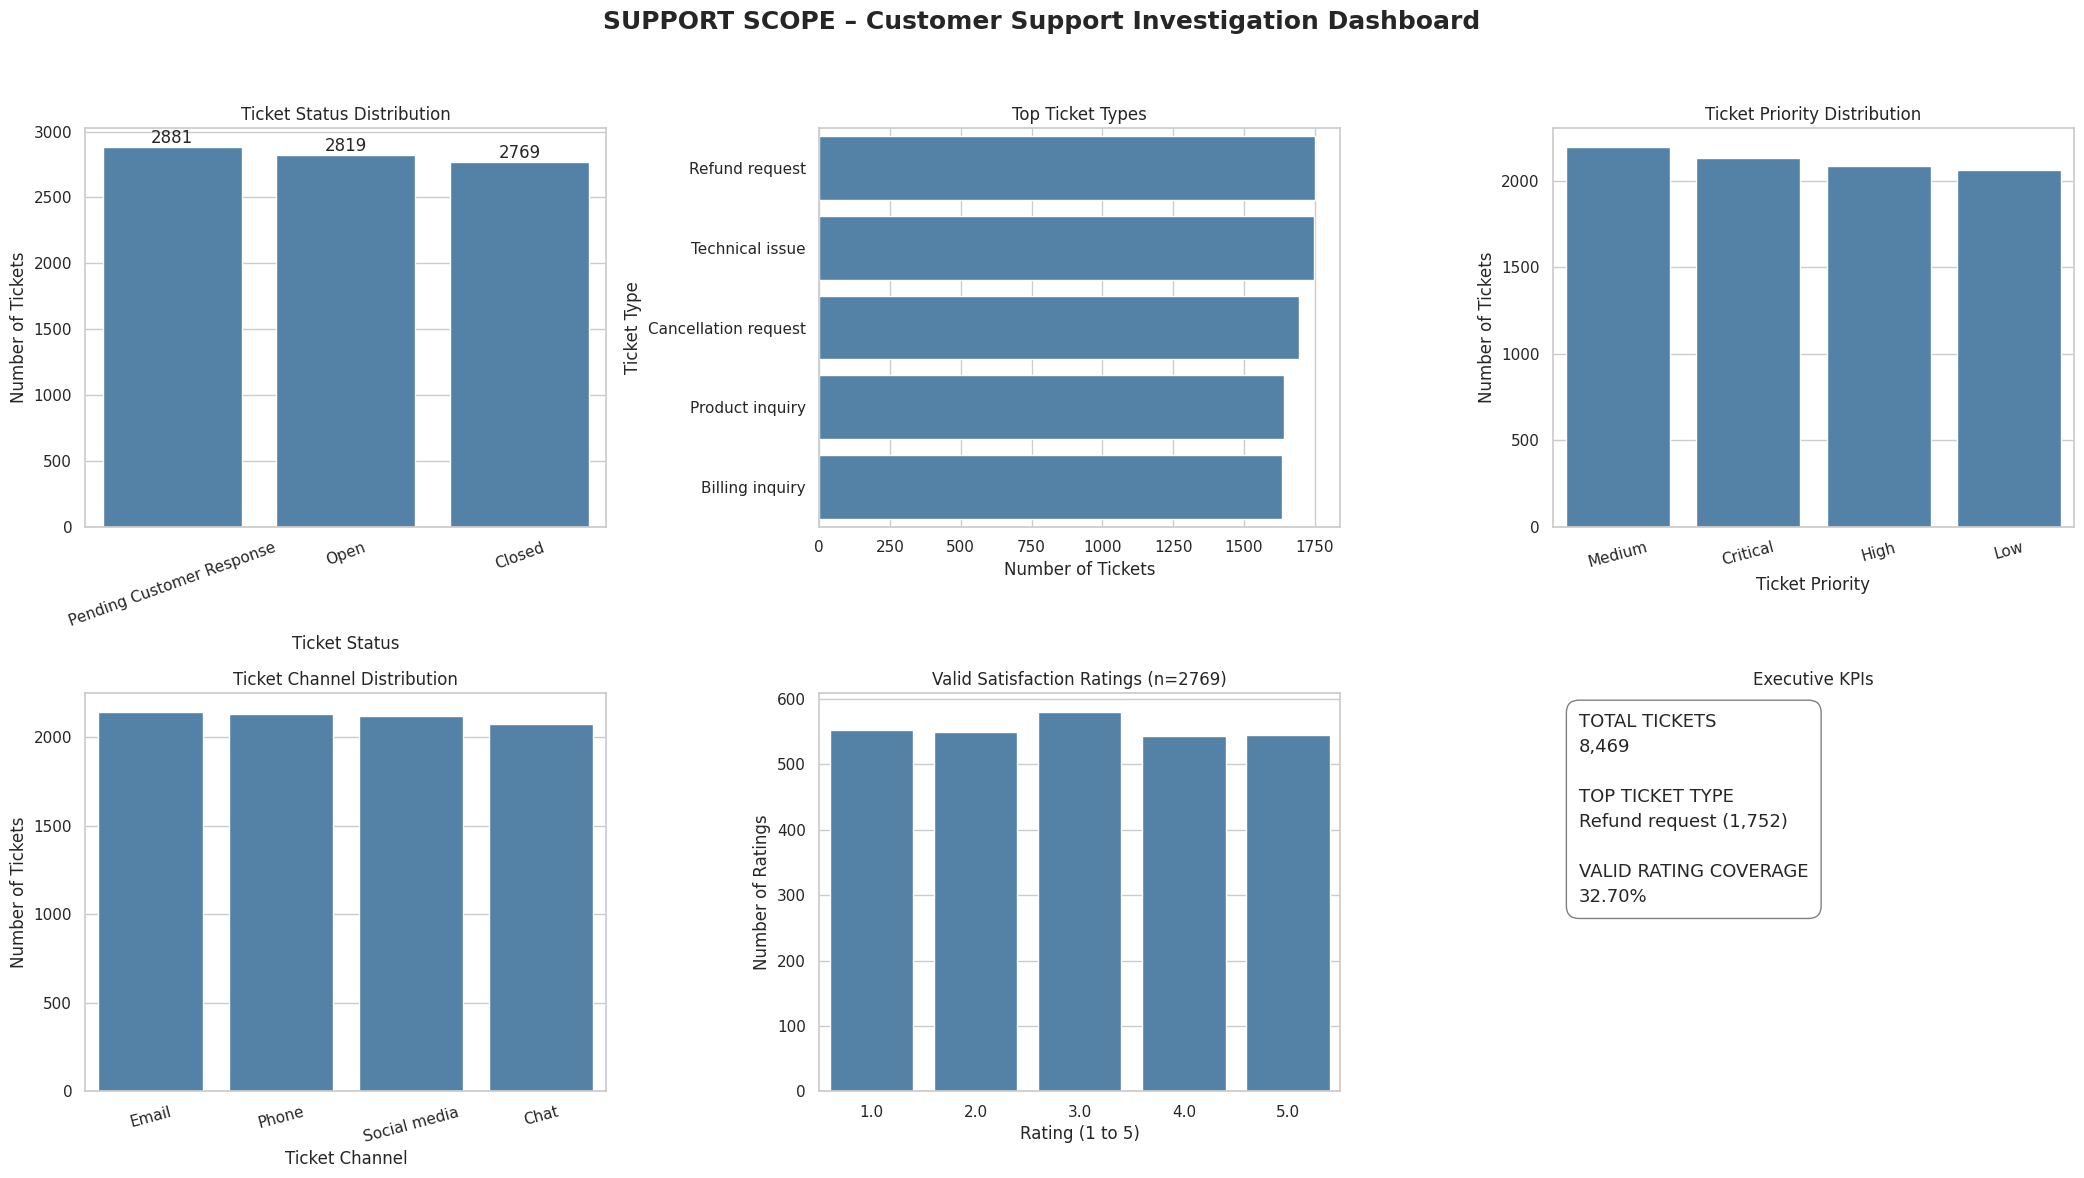

In [64]:
# Build the integrated dashboard using the verified dataset values.
sns.set_theme(style="whitegrid", font="DejaVu Sans")
fig, axes = plt.subplots(2, 3, figsize=(21, 12))
fig.suptitle(
    "SUPPORT SCOPE – Customer Support Investigation Dashboard",
    fontsize=18, fontweight="bold"
)

# Ticket status
status_counts_plot = member5_df["Ticket Status"].fillna("Missing").value_counts()
sns.barplot(
    x=status_counts_plot.index, y=status_counts_plot.values,
    ax=axes[0, 0], color="steelblue"
)
axes[0, 0].set_title("Ticket Status Distribution")
axes[0, 0].set_xlabel("Ticket Status")
axes[0, 0].set_ylabel("Number of Tickets")
axes[0, 0].tick_params(axis="x", rotation=20)
for container in axes[0, 0].containers:
    axes[0, 0].bar_label(container, fmt="%.0f")

# Ticket type
type_counts_plot = member5_df["Ticket Type"].fillna("Missing").value_counts().head(8)
sns.barplot(
    y=type_counts_plot.index, x=type_counts_plot.values,
    ax=axes[0, 1], color="steelblue"
)
axes[0, 1].set_title("Top Ticket Types")
axes[0, 1].set_xlabel("Number of Tickets")
axes[0, 1].set_ylabel("Ticket Type")

# Priority
priority_counts_plot = member5_df["Ticket Priority"].fillna("Missing").value_counts()
sns.barplot(
    x=priority_counts_plot.index, y=priority_counts_plot.values,
    ax=axes[0, 2], color="steelblue"
)
axes[0, 2].set_title("Ticket Priority Distribution")
axes[0, 2].set_xlabel("Ticket Priority")
axes[0, 2].set_ylabel("Number of Tickets")
axes[0, 2].tick_params(axis="x", rotation=15)

# Channel
channel_counts_plot = member5_df["Ticket Channel"].fillna("Missing").value_counts()
sns.barplot(
    x=channel_counts_plot.index, y=channel_counts_plot.values,
    ax=axes[1, 0], color="steelblue"
)
axes[1, 0].set_title("Ticket Channel Distribution")
axes[1, 0].set_xlabel("Ticket Channel")
axes[1, 0].set_ylabel("Number of Tickets")
axes[1, 0].tick_params(axis="x", rotation=15)

# Valid satisfaction ratings only
rating_counts_plot = rating_numeric_m5[valid_rating_mask_m5].value_counts().sort_index()
if not rating_counts_plot.empty:
    sns.barplot(
        x=rating_counts_plot.index.astype(str),
        y=rating_counts_plot.values,
        ax=axes[1, 1], color="steelblue"
    )
    axes[1, 1].set_title(
        f"Valid Satisfaction Ratings (n={valid_rating_count_m5})"
    )
    axes[1, 1].set_xlabel("Rating (1 to 5)")
    axes[1, 1].set_ylabel("Number of Ratings")
else:
    axes[1, 1].text(0.5, 0.5, "No valid ratings available",
                    ha="center", va="center")
    axes[1, 1].set_title("Customer Satisfaction")
    axes[1, 1].set_axis_off()

# KPI panel
axes[1, 2].axis("off")
kpi_text = (
    f"TOTAL TICKETS\n{total_tickets_m5:,}\n\n"
    f"TOP TICKET TYPE\n{top_type_m5[0]} ({top_type_m5[1]:,})\n\n"
    f"VALID RATING COVERAGE\n{rating_coverage_pct_m5:.2f}%"
)
axes[1, 2].text(
    0.05, 0.95, kpi_text, va="top", ha="left",
    fontsize=13, linespacing=1.5,
    bbox=dict(boxstyle="round,pad=0.7", facecolor="white", edgecolor="gray")
)
axes[1, 2].set_title("Executive KPIs")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


### 4 – Generate key findings for the presentation

### Description

Summarise the leading categories and rating coverage using the calculated values. These statements describe the observed dataset only. They do not claim that ticket volume or rating differences prove the reason behind customer behaviour or support delays.


In [65]:
# Print concise findings using only calculated results.
print("KEY FINDINGS – SUPPORT SCOPE")
print(f"1. The integrated dataset contains {total_tickets_m5:,} tickets.")

print(
    f"2. The most frequent ticket status is "
    f"{status_summary_m5.index[0]} "
    f"({int(status_summary_m5.iloc[0]['Ticket Count']):,} tickets; "
    f"{status_summary_m5.iloc[0]['Percentage']:.2f}%)."
)

print(
    f"3. The most frequent ticket type is {top_type_m5[0]} "
    f"({top_type_m5[1]:,} tickets; {top_type_m5[2]:.2f}%)."
)

print(
    f"4. The most frequent priority is {top_priority_m5[0]} "
    f"({top_priority_m5[1]:,} tickets; {top_priority_m5[2]:.2f}%)."
)

print(
    f"5. The most frequent communication channel is {top_channel_m5[0]} "
    f"({top_channel_m5[1]:,} tickets; {top_channel_m5[2]:.2f}%)."
)

print(
    f"6. Valid satisfaction ratings are available for "
    f"{valid_rating_count_m5:,} tickets "
    f"({rating_coverage_pct_m5:.2f}% of all tickets)."
)
if pd.notna(average_rating_m5):
    print(f"   Average valid satisfaction rating: {average_rating_m5:.2f} out of 5.")


KEY FINDINGS – SUPPORT SCOPE
1. The integrated dataset contains 8,469 tickets.
2. The most frequent ticket status is Pending Customer Response (2,881 tickets; 34.02%).
3. The most frequent ticket type is Refund request (1,752 tickets; 20.69%).
4. The most frequent priority is Medium (2,192 tickets; 25.88%).
5. The most frequent communication channel is Email (2,143 tickets; 25.30%).
6. Valid satisfaction ratings are available for 2,769 tickets (32.70% of all tickets).
   Average valid satisfaction rating: 2.99 out of 5.


### 5 – Prepare evidence-based recommendations

### Description

Prepare practical areas for management to investigate next. Recommendations are framed as follow-up checks, not guaranteed solutions. Each point should be reviewed alongside the relevant Member 2, Member 3 or Member 4 chart and its sample count.


In [66]:
# Create investigation recommendations based on the fields analysed by the team.
recommendations_m5 = [
    "Review the ticket status distribution and investigate categories with a large Open or Pending workload.",
    "Review the most frequent ticket types and subjects to understand where support demand is concentrated.",
    "Compare priority and channel groups using both ticket counts and Open/Pending percentages before changing staffing or routing.",
    "Improve the completeness of response-time and resolution records so future operational reporting can be more reliable.",
    "Encourage consistent collection of customer satisfaction ratings and report the valid sample size with every comparison.",
    "Review customer-age or product-level satisfaction comparisons only where the available sample size is sufficient.",
    "Recheck the dashboard after future reporting periods to see whether the observed patterns remain consistent."
]

print("MANAGEMENT INVESTIGATION RECOMMENDATIONS")
for number, recommendation in enumerate(recommendations_m5, start=1):
    print(f"{number}. {recommendation}")


MANAGEMENT INVESTIGATION RECOMMENDATIONS
1. Review the ticket status distribution and investigate categories with a large Open or Pending workload.
2. Review the most frequent ticket types and subjects to understand where support demand is concentrated.
3. Compare priority and channel groups using both ticket counts and Open/Pending percentages before changing staffing or routing.
4. Improve the completeness of response-time and resolution records so future operational reporting can be more reliable.
5. Encourage consistent collection of customer satisfaction ratings and report the valid sample size with every comparison.
6. Review customer-age or product-level satisfaction comparisons only where the available sample size is sufficient.
7. Recheck the dashboard after future reporting periods to see whether the observed patterns remain consistent.


### 6 – Export Member 5 outputs

### Description

Save the executive summary, ticket status summary, key findings, recommendations and dashboard image in a dedicated results folder. These files can be shared with the team and inserted into the final presentation. The original customer-support CSV remains unchanged.


In [67]:
# Save Member 5 summary tables, findings and dashboard image.
member5_folder = "member5_results"
os.makedirs(member5_folder, exist_ok=True)

executive_summary_m5.to_csv(
    os.path.join(member5_folder, "executive_summary.csv"), index=False
)
status_summary_m5.to_csv(
    os.path.join(member5_folder, "ticket_status_summary.csv")
)

findings_lines_m5 = [
    f"Total tickets: {total_tickets_m5:,}",
    f"Top ticket type: {top_type_m5[0]} – {top_type_m5[1]:,} ({top_type_m5[2]:.2f}%)",
    f"Top ticket subject: {top_subject_m5[0]} – {top_subject_m5[1]:,} ({top_subject_m5[2]:.2f}%)",
    f"Top priority: {top_priority_m5[0]} – {top_priority_m5[1]:,} ({top_priority_m5[2]:.2f}%)",
    f"Top channel: {top_channel_m5[0]} – {top_channel_m5[1]:,} ({top_channel_m5[2]:.2f}%)",
    f"Valid satisfaction ratings: {valid_rating_count_m5:,} ({rating_coverage_pct_m5:.2f}%)",
    f"Average valid satisfaction rating: {average_rating_m5}"
]
with open(os.path.join(member5_folder, "key_findings.txt"), "w", encoding="utf-8") as file:
    file.write("\n".join(findings_lines_m5))

with open(os.path.join(member5_folder, "recommendations.txt"), "w", encoding="utf-8") as file:
    file.write("\n".join(
        f"{number}. {item}"
        for number, item in enumerate(recommendations_m5, start=1)
    ))

fig.savefig(
    os.path.join(member5_folder, "support_scope_dashboard.png"),
    dpi=300, bbox_inches="tight"
)

print("Member 5 output files saved in:", member5_folder)
print("Files: executive_summary.csv, ticket_status_summary.csv,")
print("       key_findings.txt, recommendations.txt, support_scope_dashboard.png")


Member 5 output files saved in: member5_results
Files: executive_summary.csv, ticket_status_summary.csv,
       key_findings.txt, recommendations.txt, support_scope_dashboard.png


### 7 – Metric traceability and reconciliation checks

### Description

List every major KPI with its definition, the source columns, the section where it was first calculated and its value. The values are **recalculated directly from the analytical dataset** (`member5_df`), so each number can be traced back to its formula.

A second table then reconciles the figures reported by Members 2–5 (for example, category counts must add up to the total number of tickets). The traceability table is also saved as `metric_traceability.csv` in the `member5_results` folder.

Response and resolution durations and SLA performance are listed as *not calculated* because the dataset has no documented start/end timestamp pair.

In [68]:
# MEMBER 5 – METRIC TRACEABILITY AND RECONCILIATION CHECKS
# Every KPI is recalculated directly from member5_df so it can be traced to a formula.
total = len(member5_df)
unresolved_flag = member5_df["Ticket Status"].isin(["Open", "Pending Customer Response"])
unresolved = int(unresolved_flag.sum())
status_counts = member5_df["Ticket Status"].value_counts()

rating = pd.to_numeric(member5_df["Customer Satisfaction Rating"], errors="coerce")
valid_rating = rating.between(1, 5)
response_available = int(member5_df["First Response Time"].notna().sum())
resolution_available = int(member5_df["Time to Resolution"].notna().sum())


def top_of(column):
    counts = member5_df[column].value_counts()
    return f"{counts.index[0]} ({int(counts.iloc[0]):,} tickets; {counts.iloc[0] / total * 100:.2f}%)"


def highest_unresolved_share(column):
    grouped = unresolved_flag.groupby(member5_df[column]).agg(["sum", "count"])
    share = grouped["sum"] / grouped["count"] * 100
    name = share.idxmax()
    return (f"{name} ({int(grouped.loc[name, 'sum']):,} of "
            f"{int(grouped.loc[name, 'count']):,}; {share[name]:.2f}%)")


metric_traceability = pd.DataFrame([
    ["Total tickets", "Number of rows (each row is one unique Ticket ID)",
     "Ticket ID", "Member 1 (12); Member 5 (2)", f"{total:,}"],
    ["Ticket status distribution", "Tickets in status ÷ total tickets × 100",
     "Ticket Status", "Member 2 (6, 8); Member 5 (2)",
     "; ".join(f"{k}: {v:,} ({v / total * 100:.2f}%)" for k, v in status_counts.items())],
    ["Open + Pending workload", "(Open + Pending Customer Response) ÷ total tickets × 100",
     "Ticket Status", "Member 3 (12)",
     f"{unresolved:,} of {total:,} ({unresolved / total * 100:.2f}%)"],
    ["Most frequent ticket type", "Ticket type with the highest ticket count",
     "Ticket Type", "Member 2 (4)", top_of("Ticket Type")],
    ["Most frequent ticket subject", "Ticket subject with the highest ticket count",
     "Ticket Subject", "Member 2 (5)", top_of("Ticket Subject")],
    ["Most frequent priority", "Priority with the highest ticket count",
     "Ticket Priority", "Member 3 (2)", top_of("Ticket Priority")],
    ["Most frequent channel", "Channel with the highest ticket count",
     "Ticket Channel", "Member 3 (4)", top_of("Ticket Channel")],
    ["Highest Open/Pending share by priority",
     "Open/Pending tickets ÷ tickets in that priority × 100",
     "Ticket Priority, Ticket Status", "Member 3 (12)",
     highest_unresolved_share("Ticket Priority")],
    ["Highest Open/Pending share by channel",
     "Open/Pending tickets ÷ tickets in that channel × 100",
     "Ticket Channel, Ticket Status", "Member 3 (12)",
     highest_unresolved_share("Ticket Channel")],
    ["First Response Time coverage", "Non-missing values ÷ total tickets × 100",
     "First Response Time", "Member 4 (1)",
     f"{response_available:,} of {total:,} ({response_available / total * 100:.2f}%)"],
    ["Time to Resolution coverage", "Non-missing values ÷ total tickets × 100",
     "Time to Resolution", "Member 4 (1)",
     f"{resolution_available:,} of {total:,} ({resolution_available / total * 100:.2f}%)"],
    ["Valid satisfaction rating coverage",
     "Ratings from 1 to 5 ÷ total tickets × 100",
     "Customer Satisfaction Rating", "Member 4 (4); Member 5 (2)",
     f"{int(valid_rating.sum()):,} of {total:,} ({valid_rating.sum() / total * 100:.2f}%)"],
    ["Average satisfaction rating",
     "Mean of valid ratings only (missing ratings are never treated as zero)",
     "Customer Satisfaction Rating", "Member 4 (4); Member 5 (2)",
     f"{rating[valid_rating].mean():.2f} out of 5"],
    ["Response / resolution duration and SLA",
     "Not calculated: no ticket-created timestamp or documented start/end pair",
     "First Response Time, Time to Resolution", "Member 4 (10)", "Not calculated"],
], columns=["KPI", "Definition / formula", "Source columns",
            "Section (Member and step)", "Value"])

with pd.option_context("display.max_colwidth", None, "display.width", 250):
    display(metric_traceability)

# Reconcile the figures reported by the different members.
reconciliation_checks = {
    "Status counts add up to total tickets": int(status_counts.sum()) == total,
    "Priority counts (Member 3) add up to total tickets":
        int(priority_summary["Ticket Count"].sum()) == total,
    "Channel counts (Member 3) add up to total tickets":
        int(channel_summary["Ticket Count"].sum()) == total,
    "Ticket IDs are unique": bool(member5_df["Ticket ID"].is_unique),
    "Valid + missing ratings equal total tickets":
        int(valid_rating.sum()) + int((~valid_rating).sum()) == total,
    "Valid-rating count matches Member 4": int(valid_rating.sum()) == valid_rating_count,
    "Age-group sample counts add up to valid ratings":
        int(satisfaction_by_age["Sample_Count"].sum()) == int(valid_rating.sum()),
    "Average rating matches Member 4":
        round(float(rating[valid_rating].mean()), 2)
        == round(float(valid_ratings["Satisfaction Numeric"].mean()), 2),
}

print("RECONCILIATION CHECKS")
for check_name, passed in reconciliation_checks.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {check_name}")
print("All checks passed." if all(reconciliation_checks.values())
      else "Some checks failed – review the sections above.")

metric_traceability.to_csv(
    os.path.join(member5_folder, "metric_traceability.csv"), index=False
)
print("Metric traceability table saved in:", member5_folder)

,KPI,Definition / formula,Source columns,Section (Member and step),Value
0,Total tickets,Number of rows (each row is one unique Ticket ID),Ticket ID,Member 1 (12); Member 5 (2),"8,469"
1,Ticket status distribution,Tickets in status ÷ total tickets × 100,Ticket Status,"Member 2 (6, 8); Member 5 (2)","Pending Customer Response: 2,881 (34.02%); Open: 2,819 (33.29%); Closed: 2,769 (32.70%)"
2,Open + Pending workload,(Open + Pending Customer Response) ÷ total tickets × 100,Ticket Status,Member 3 (12),"5,700 of 8,469 (67.30%)"
3,Most frequent ticket type,Ticket type with the highest ticket count,Ticket Type,Member 2 (4),"Refund request (1,752 tickets; 20.69%)"
4,Most frequent ticket subject,Ticket subject with the highest ticket count,Ticket Subject,Member 2 (5),Refund request (576 tickets; 6.80%)
5,Most frequent priority,Priority with the highest ticket count,Ticket Priority,Member 3 (2),"Medium (2,192 tickets; 25.88%)"
6,Most frequent channel,Channel with the highest ticket count,Ticket Channel,Member 3 (4),"Email (2,143 tickets; 25.30%)"
7,Highest Open/Pending share by priority,Open/Pending tickets ÷ tickets in that priority × 100,"Ticket Priority, Ticket Status",Member 3 (12),"Low (1,419 of 2,063; 68.78%)"
8,Highest Open/Pending share by channel,Open/Pending tickets ÷ tickets in that channel × 100,"Ticket Channel, Ticket Status",Member 3 (12),"Social media (1,437 of 2,121; 67.75%)"
9,First Response Time coverage,Non-missing values ÷ total tickets × 100,First Response Time,Member 4 (1),"5,650 of 8,469 (66.71%)"


RECONCILIATION CHECKS
[PASS] Status counts add up to total tickets
[PASS] Priority counts (Member 3) add up to total tickets
[PASS] Channel counts (Member 3) add up to total tickets
[PASS] Ticket IDs are unique
[PASS] Valid + missing ratings equal total tickets
[PASS] Valid-rating count matches Member 4
[PASS] Age-group sample counts add up to valid ratings
[PASS] Average rating matches Member 4
All checks passed.
Metric traceability table saved in: member5_results


### Member 5 – Final conclusion

Member 5 integrates the team's verified analysis into a single SUPPORT SCOPE dashboard and executive summary. The dashboard presents ticket workload, status, ticket type, priority, communication channel and valid satisfaction-rating coverage. The exported findings and recommendations support the final presentation. All conclusions are descriptive, use actual dataset values and respect the limitations identified by Members 1–4.
